# QQQ Volatility Forecasting: Classification and Clustering

**เล่มนี้ตอบคำถาม:** โมเดลบอกล่วงหน้าได้ไหมว่า 5 วันทำการข้างหน้าจะเป็นช่วง "ผันผวนสูง"

**ขอบเขต**

- classifier 13 ตัว และ clustering 2 ตัว ทุกตัวเขียนเองด้วย NumPy
- เล่มนี้ **อ่านผลที่เทรนไว้แล้ว** จาก `outputs/modeling/` ไม่เทรนใหม่ และไม่เปิด Test set
- ตัวเลขทุกตัววัดบน Validation ผลบน Test อยู่ใน `05_results_comparison.ipynb`
- หัวข้อ 16 เพิ่ม RBF Kernel Perceptron หลังส่งงาน พร้อมกราฟและ leaderboard เสริมที่แยกจากผล 13 classifiers เดิม
- หัวข้อ 17 เพิ่มการทดลอง transfer learning หลังนำเสนอ (Transformer/GRU ที่ pretrain บน ETF 10 ตัว) บน Validation โดยแยกจาก leaderboard เดิม

**ต้องรันอะไรก่อน:** `python -m src.ml.run report`, `compare` และ `analyze` (ดู `docs/guides/RUNBOOK.md`)

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

current = Path.cwd().resolve()
project_root = current.parent if current.name == "notebooks" else current
if not (project_root / "config.py").is_file() or not (project_root / "src").is_dir():
    raise FileNotFoundError(f"Could not resolve project root from {current}; expected config.py and src/.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.ml.core.artifacts import load_model, read_run, read_runs
from src.ml.core.compare import assert_parity
from src.ml.core.contracts import FEATURE_COLUMNS, VARIANTS
from src.ml.core.data import load
from src.ml.core.trainer import OUTPUT_ROOT, evaluate

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
REPORT_ROOT = OUTPUT_ROOT / "report"
FIGURE_ROOT = project_root / "outputs" / "figures" / "modeling"
TASK = 'classification'


def require_files(paths):
    missing = [str(path) for path in paths if not Path(path).is_file()]
    if missing:
        raise FileNotFoundError(
            "Missing generated artifacts (run `python -m src.ml.run report/compare/analyze` first):\n"
            + "\n".join(missing)
        )


def table(path):
    require_files([path])
    return pd.read_csv(path)


# src.ml.core.figures selects the file-only Agg backend; switch back so charts drawn in
# this notebook are shown inline.
get_ipython().run_line_magic("matplotlib", "inline")


def show_markdown(path):
    require_files([path])
    display(Markdown(Path(path).read_text(encoding="utf-8")))


def show_image(path, width=900):
    require_files([path])
    display(Image(filename=str(path), width=width))

## 1. โจทย์และความไม่สมดุลของคลาส

เราเปลี่ยนค่าความผันผวนเป็นคำตอบ ใช่/ไม่ใช่:

- `target_high_volatility = 1` เมื่อ `target_volatility_5d` **มากกว่า** Q75 ของ Train (0.2531)
- ไม่อย่างนั้นเป็น 0

Q75 คือค่าที่ 75% ของวันใน Train อยู่ต่ำกว่า เราคำนวณจาก **Train เท่านั้น** แล้วใช้เส้นเดียวกันกับ Validation และ Test เพื่อไม่ให้ข้อมูลอนาคตรั่วเข้ามา

ผลคือ Train มีวันผันผวนสูงราว 25% ตามนิยาม แต่ Validation ไม่จำเป็นต้องเป็น 25% ดูตารางถัดไป

In [2]:
data = {variant: load(variant) for variant in VARIANTS}
balance = []
for variant, dataset in data.items():
    y = dataset.train.y_classification
    balance.append({"split": f"train ({variant})", "rows": len(y), "high-volatility days": int(y.sum()),
                    "positive rate": y.mean()})
y = data["with_spike"].validation.y_classification
balance.append({"split": "validation (shared)", "rows": len(y), "high-volatility days": int(y.sum()),
                "positive rate": y.mean()})
display(pd.DataFrame(balance).style.format({"positive rate": "{:.1%}"}))
print("Q75 threshold fitted on Train:", data["with_spike"].threshold)

,split,rows,high-volatility days,positive rate
0,train (with_spike),1733,433,25.0%
1,train (non_spike),1520,280,18.4%
2,validation (shared),371,34,9.2%


Q75 threshold fitted on Train: 0.2530580184684854


**อ่านตาราง:** Validation มีวันผันผวนสูงเพียง 34 จาก 371 วัน (9.2%) น้อยกว่า Train มาก ตัวเลขนี้กำหนดทุกอย่างที่ตามมา: คะแนนทุกตัวตั้งอยู่บนวัน positive 34 วัน ความไม่แน่นอนจึงสูง

## 2. ทำไม accuracy ใช้เดี่ยว ๆ ไม่ได้

ถ้าโมเดลตอบว่า "ไม่ผันผวน" ทุกวันโดยไม่ดูข้อมูลเลย จะตอบถูก 337 จาก 371 วัน = **accuracy 90.8%** ทั้งที่จับวันผันผวนสูงไม่ได้สักวัน

accuracy สูงจึงไม่ได้แปลว่าโมเดลดี เราต้องดู metric ที่สนใจคลาสส่วนน้อยโดยเฉพาะ

## 3. อภิธานศัพท์ metric

confusion matrix แบ่งคำทำนายเป็น 4 ช่อง:

| | ทำนายว่าไม่ผันผวน (0) | ทำนายว่าผันผวนสูง (1) |
| --- | --- | --- |
| **จริง ๆ ไม่ผันผวน** | TN (ถูก) | FP (เตือนผิด) |
| **จริง ๆ ผันผวนสูง** | FN (พลาด) | TP (จับได้) |

| Metric | สูตร | ตอบคำถามว่า |
| --- | --- | --- |
| **Precision** | TP / (TP + FP) | เวลาโมเดลเตือน เชื่อได้แค่ไหน |
| **Sensitivity (= Recall)** | TP / (TP + FN) | วันผันผวนสูงจริง โมเดลจับได้กี่ส่วน |
| **Specificity (= TNR)** | TN / (TN + FP) | วันปกติ โมเดลไม่เตือนผิดกี่ส่วน |
| **F1** | 2·P·R / (P + R) | สมดุลระหว่าง precision กับ recall |
| **ROC-AUC** | พื้นที่ใต้กราฟ ROC | สุ่มวันผันผวนสูงมา 1 วัน กับวันปกติ 1 วัน โมเดลให้คะแนนวันผันผวนสูงมากกว่าด้วยโอกาสเท่าไร (0.5 = เดาสุ่ม) |
| **Average precision (AP)** | พื้นที่ใต้กราฟ precision-recall | คุณภาพการจัดอันดับโดยเน้นคลาสส่วนน้อย (ค่าของการเดาสุ่ม = positive rate = 0.092) |

โจทย์ระบุ specificity และ TNR แยกกัน ทั้งสองคือค่าเดียวกัน เราจึงพิมพ์สองคอลัมน์ที่มีค่าเท่ากัน

**AP เป็น metric หลัก** ที่ใช้เลือกการตั้งค่าของ classifier ทุกตัว เพราะคลาสไม่สมดุลและเราสนใจคลาสส่วนน้อย

**threshold คงที่:** โมเดลที่ให้ค่าความน่าจะเป็นตัดที่ 0.5 ส่วนโมเดลที่ให้ decision score ตัดที่ 0 เรา **ไม่ปรับ threshold บน Validation** เพื่อไม่เพิ่มการเลือกบนข้อมูลชุดเดียวกันอีกชั้น

ตารางถัดไปคือการตั้งค่าที่ชนะของแต่ละโมเดล

In [3]:
runs = {variant: read_runs(OUTPUT_ROOT, variant, task=TASK) for variant in VARIANTS}
chosen = []
for variant, items in runs.items():
    for run in items:
        search = json.loads((run.directory / "search_results.json").read_text(encoding="utf-8"))
        chosen.append({"variant": variant, "model": run.name, "candidates tried": len(search),
                       "selected": run.config["selected_candidate"], "params": json.dumps(run.config["params"]),
                       "preprocess": run.config["preprocess"], "pca_components": run.config["pca_components"],
                       "score_kind": run.metrics["score_kind"]})
with pd.option_context("display.max_rows", 40):
    display(pd.DataFrame(chosen))

,variant,model,candidates tried,selected,params,preprocess,pca_components,score_kind
0,with_spike,adaboost,6,adaboost-02,"{""learning_rate"": 0.5, ""n_estimators"": 100, ""random_state"": 42}",none,NaN,probability
1,with_spike,decision_tree,6,decision_tree-00,"{""max_depth"": 2, ""max_features"": null, ""min_samples_leaf"": 5, ""random_state""...",none,NaN,probability
2,with_spike,gaussian_nb,3,gaussian_nb-02,"{""var_smoothing"": 1e-07}",none,NaN,probability
3,with_spike,gradient_boosting,8,gradient_boosting-04,"{""learning_rate"": 0.1, ""max_depth"": 1, ""min_samples_leaf"": 5, ""n_estimators""...",none,NaN,probability
4,with_spike,knn,8,knn-07,"{""k"": 15, ""weights"": ""distance""}",standardize,NaN,probability
5,with_spike,logistic,6,logistic-02,"{""class_weight"": null, ""l2"": 0.01, ""learning_rate"": 0.05, ""max_iter"": 5000, ...",standardize,NaN,probability
6,with_spike,mlp,12,mlp-00,"{""activation"": ""relu"", ""batch"": 32, ""hidden_layers"": [16], ""l2"": 0, ""learnin...",standardize,NaN,probability
7,with_spike,perceptron,3,perceptron-00,"{""learning_rate"": 0.001, ""max_epochs"": 1000}",standardize,NaN,decision
8,with_spike,random_forest,7,random_forest-01,"{""bootstrap"": true, ""max_depth"": 3, ""max_features"": ""sqrt"", ""min_samples_lea...",none,NaN,probability
9,with_spike,slp,8,slp-00,"{""batch"": 32, ""l2"": 0, ""learning_rate"": 0.001, ""max_epochs"": 1000, ""min_delt...",standardize,NaN,probability


## 4. Leaderboard บน Validation

**วิธีอ่าน**

- คอลัมน์ `_ci` เขียนเป็น `ค่า [ต่ำ, สูง]` วงเล็บคือช่วงความเชื่อมั่น 95% จาก block bootstrap (สุ่มซ้ำเป็นก้อน 20 วันติดกัน 2,000 รอบ)
- `tied_with_leader = yes` แปลว่าแยกจากอันดับ 1 ไม่ได้ทางสถิติ **ห้ามอ้างอันดับภายในกลุ่มนี้**
- `beats_best_baseline` เทียบ AP กับ baseline ตัวที่ดีที่สุด
- แถว `baseline_majority` คือการตอบ "ไม่ผันผวน" ทุกวัน และ `baseline_persistence` คือการใช้ความผันผวน 5 วันที่ผ่านมาเป็นคะแนนตรง ๆ โดยไม่เทรนอะไร
- ตัวเลขทั้งหมดเป็น **selection score** จึงดูดีกว่าความจริงเล็กน้อย

In [4]:
for variant in VARIANTS:
    show_markdown(REPORT_ROOT / variant / "leaderboard_classification.md")

### Validation leaderboard — classification — with_spike

| model | kind | average_precision_ci | roc_auc_ci | f1_ci | recall_ci | precision | specificity | accuracy | loss_name | loss | tied_with_leader | beats_best_baseline |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| mlp | model | 0.2668 [0.0579, 0.4724] | 0.6757 [0.3961, 0.8474] | 0.3200 [0.0000, 0.5556] | 0.2353 [0.0000, 0.4889] | 0.5000 | 0.9763 | 0.9084 | binary_cross_entropy | 0.3359 | yes | yes |
| random_forest | model | 0.2548 [0.0603, 0.4586] | 0.6862 [0.4634, 0.8323] | 0.2917 [0.0000, 0.5051] | 0.2059 [0.0000, 0.4255] | 0.5000 | 0.9792 | 0.9084 | log_loss | 0.3131 | yes | yes |
| gradient_boosting | model | 0.2531 [0.0548, 0.4746] | 0.6754 [0.4075, 0.8409] | 0.2449 [0.0000, 0.4330] | 0.1765 [0.0000, 0.3674] | 0.4000 | 0.9733 | 0.9003 | binary_logistic_loss | 0.3075 | yes | yes |
| svm | model | 0.2514 [0.0514, 0.4651] | 0.6786 [0.4339, 0.8404] | 0.2553 [0.0000, 0.4445] | 0.1765 [0.0000, 0.3674] | 0.4615 | 0.9792 | 0.9057 | hinge_loss | 0.2688 | yes | yes |
| xgboost | model | 0.2508 [0.0559, 0.4681] | 0.6693 [0.4080, 0.8368] | 0.2449 [0.0000, 0.4424] | 0.1765 [0.0000, 0.3674] | 0.4000 | 0.9733 | 0.9003 | binary_logistic_loss | 0.3263 | yes | yes |
| baseline_persistence | baseline | 0.2474 [0.0545, 0.5002] | 0.7214 [0.5384, 0.8407] | 0.2899 [0.0000, 0.5589] | 0.2941 [0.0000, 0.5601] | 0.2857 | 0.9258 | 0.8679 | n/a | n/a | yes | n/a |
| slp | model | 0.2427 [0.0545, 0.4432] | 0.6803 [0.4458, 0.8289] | 0.2609 [0.0000, 0.4615] | 0.1765 [0.0000, 0.3674] | 0.5000 | 0.9822 | 0.9084 | binary_cross_entropy | 0.3046 | yes | no |
| adaboost | model | 0.2363 [0.0626, 0.4381] | 0.6768 [0.4602, 0.8196] | 0.2222 [0.0000, 0.4226] | 0.1765 [0.0000, 0.3674] | 0.3000 | 0.9585 | 0.8868 | exponential_loss | 0.5771 | yes | no |
| logistic | model | 0.2330 [0.0526, 0.4301] | 0.6732 [0.4224, 0.8305] | 0.2609 [0.0000, 0.4615] | 0.1765 [0.0000, 0.3674] | 0.5000 | 0.9822 | 0.9084 | binary_cross_entropy | 0.3089 | yes | no |
| stacking | model | 0.2262 [0.0551, 0.4176] | 0.6641 [0.4218, 0.8155] | 0.2353 [0.0000, 0.4000] | 0.1765 [0.0000, 0.3674] | 0.3529 | 0.9674 | 0.8949 | log_loss | 0.3455 | yes | no |
| gaussian_nb | model | 0.2218 [0.0464, 0.4333] | 0.6665 [0.4217, 0.8214] | 0.2812 [0.0000, 0.5001] | 0.2647 [0.0000, 0.5228] | 0.3000 | 0.9377 | 0.8760 | log_loss | 0.6203 | yes | no |
| knn | model | 0.2037 [0.0610, 0.4015] | 0.6987 [0.5068, 0.8179] | 0.2000 [0.0000, 0.3509] | 0.1471 [0.0000, 0.3077] | 0.3125 | 0.9674 | 0.8922 | log_loss | 0.6345 | yes | no |
| decision_tree | model | 0.1732 [0.0494, 0.3562] | 0.6418 [0.4752, 0.7795] | 0.3099 [0.0000, 0.5094] | 0.3235 [0.0000, 0.5610] | 0.2973 | 0.9228 | 0.8679 | log_loss | 0.3350 | yes | no |
| baseline_majority | baseline | 0.0916 [0.0350, 0.1779] | 0.5000 [0.5000, 0.5000] | 0.0000 [0.0000, 0.0000] | 0.0000 [0.0000, 0.0000] | n/a | 1.0000 | 0.9084 | n/a | n/a | no | n/a |
| perceptron | model | 0.0648 [0.0310, 0.1334] | 0.2993 [0.1807, 0.4718] | 0.0000 [0.0000, 0.0000] | 0.0000 [0.0000, 0.0000] | 0.0000 | 0.9644 | 0.8760 | perceptron_criterion | 0.0008 | yes | no |

> ตัวเลขบน Validation เป็น selection score: hyperparameter ของทุกโมเดลถูกเลือกบนแถวชุดนี้ จึงมองโลกในแง่ดีเกินจริง และโมเดลที่ `tied_with_leader = yes` แยกจากอันดับ 1 ไม่ได้ที่ระดับ 95% (moving-block bootstrap, block 20 วัน) ห้ามอ้างอันดับภายในกลุ่มนั้น
> 13 จาก 13 โมเดลอยู่ในกลุ่มที่แยกจากอันดับ 1 ไม่ได้


### Validation leaderboard — classification — non_spike

| model | kind | average_precision_ci | roc_auc_ci | f1_ci | recall_ci | precision | specificity | accuracy | loss_name | loss | tied_with_leader | beats_best_baseline |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| random_forest | model | 0.3010 [0.0548, 0.5328] | 0.6766 [0.4439, 0.8313] | 0.2917 [0.0000, 0.5064] | 0.2059 [0.0000, 0.4287] | 0.5000 | 0.9792 | 0.9084 | log_loss | 0.3059 | yes | yes |
| mlp | model | 0.2808 [0.0534, 0.5184] | 0.6992 [0.4716, 0.8426] | 0.3077 [0.0000, 0.5435] | 0.2353 [0.0000, 0.4545] | 0.4444 | 0.9703 | 0.9030 | binary_cross_entropy | 0.3166 | yes | yes |
| xgboost | model | 0.2652 [0.0600, 0.4730] | 0.6853 [0.4608, 0.8256] | 0.2800 [0.0000, 0.5000] | 0.2059 [0.0000, 0.4255] | 0.4375 | 0.9733 | 0.9030 | binary_logistic_loss | 0.3088 | yes | yes |
| gradient_boosting | model | 0.2525 [0.0625, 0.4477] | 0.6732 [0.4577, 0.8152] | 0.2667 [0.0000, 0.4533] | 0.1765 [0.0000, 0.3674] | 0.5455 | 0.9852 | 0.9111 | binary_logistic_loss | 0.2966 | yes | yes |
| logistic | model | 0.2513 [0.0538, 0.4557] | 0.6824 [0.4529, 0.8310] | 0.2553 [0.0000, 0.4445] | 0.1765 [0.0000, 0.3674] | 0.4615 | 0.9792 | 0.9057 | binary_cross_entropy | 0.3014 | yes | yes |
| svm | model | 0.2501 [0.0520, 0.4672] | 0.6804 [0.4367, 0.8413] | 0.2727 [0.0000, 0.4667] | 0.1765 [0.0000, 0.3674] | 0.6000 | 0.9881 | 0.9137 | hinge_loss | 0.2539 | yes | yes |
| baseline_persistence | baseline | 0.2474 [0.0545, 0.5002] | 0.7214 [0.5384, 0.8407] | 0.2899 [0.0000, 0.5589] | 0.2941 [0.0000, 0.5601] | 0.2857 | 0.9258 | 0.8679 | n/a | n/a | yes | n/a |
| slp | model | 0.2474 [0.0489, 0.4531] | 0.6778 [0.4892, 0.8122] | 0.2258 [0.0000, 0.4156] | 0.2059 [0.0000, 0.4255] | 0.2500 | 0.9377 | 0.8706 | binary_cross_entropy | 0.3607 | yes | no |
| adaboost | model | 0.2407 [0.0556, 0.4722] | 0.6409 [0.3618, 0.8209] | 0.2353 [0.0000, 0.4444] | 0.1765 [0.0000, 0.3674] | 0.3529 | 0.9674 | 0.8949 | exponential_loss | 0.5875 | yes | no |
| stacking | model | 0.2311 [0.0582, 0.4204] | 0.6650 [0.4550, 0.8061] | 0.1961 [0.0000, 0.3509] | 0.1471 [0.0000, 0.3077] | 0.2941 | 0.9644 | 0.8895 | log_loss | 0.3304 | yes | no |
| gaussian_nb | model | 0.2292 [0.0485, 0.4434] | 0.6789 [0.4426, 0.8273] | 0.2381 [0.0000, 0.4355] | 0.2941 [0.0000, 0.5371] | 0.2000 | 0.8813 | 0.8275 | log_loss | 0.7534 | yes | no |
| knn | model | 0.2082 [0.0584, 0.3932] | 0.6455 [0.4610, 0.7802] | 0.2222 [0.0000, 0.3846] | 0.1765 [0.0000, 0.3514] | 0.3000 | 0.9585 | 0.8868 | log_loss | 1.2326 | yes | no |
| decision_tree | model | 0.1887 [0.0505, 0.4105] | 0.6924 [0.4917, 0.8233] | 0.1887 [0.0000, 0.3556] | 0.1471 [0.0000, 0.2963] | 0.2632 | 0.9585 | 0.8841 | log_loss | 0.5063 | yes | no |
| baseline_majority | baseline | 0.0916 [0.0350, 0.1779] | 0.5000 [0.5000, 0.5000] | 0.0000 [0.0000, 0.0000] | 0.0000 [0.0000, 0.0000] | n/a | 1.0000 | 0.9084 | n/a | n/a | yes | n/a |
| perceptron | model | 0.0742 [0.0343, 0.1688] | 0.3383 [0.1803, 0.5693] | 0.1159 [0.0000, 0.2571] | 0.1176 [0.0000, 0.3125] | 0.1143 | 0.9080 | 0.8356 | perceptron_criterion | 0.0010 | yes | no |

> ตัวเลขบน Validation เป็น selection score: hyperparameter ของทุกโมเดลถูกเลือกบนแถวชุดนี้ จึงมองโลกในแง่ดีเกินจริง และโมเดลที่ `tied_with_leader = yes` แยกจากอันดับ 1 ไม่ได้ที่ระดับ 95% (moving-block bootstrap, block 20 วัน) ห้ามอ้างอันดับภายในกลุ่มนั้น
> 13 จาก 13 โมเดลอยู่ในกลุ่มที่แยกจากอันดับ 1 ไม่ได้


**สิ่งที่ตารางบอก**

- ช่วงความเชื่อมั่นกว้างมาก (AP ตั้งแต่ราว 0.05 ถึง 0.47) เพราะมีวัน positive แค่ 34 วัน และกระจุกตัวในช่วงเวลาเดียว
- เกือบทุกโมเดลอยู่ในกลุ่ม `tied_with_leader` ข้อมูล Validation จึง **ไม่พอจะตัดสินว่าโมเดลไหนดีที่สุด**
- `baseline_persistence` ซึ่งไม่ได้เรียนรู้อะไรเลย อยู่กลางตารางด้าน AP และได้ ROC-AUC สูงกว่าทุกโมเดล แปลว่า feature ตัวเดียว (`historical_volatility_5d`) ให้ข้อมูลเกือบทั้งหมดที่โมเดลใช้
- `perceptron` ได้ ROC-AUC ต่ำกว่า 0.5 คือจัดอันดับกลับด้าน และไม่ทำนาย positive ถูกเลย

ตารางถัดไปแสดง metric ครบทุกตัวที่โจทย์ระบุ

In [5]:
required = ["model", "loss_name", "loss", "tn", "fp", "fn", "tp", "accuracy", "precision", "sensitivity",
            "specificity", "tnr", "f1", "roc_auc", "average_precision"]
for variant in VARIANTS:
    full = table(REPORT_ROOT / variant / "leaderboard_classification.csv")
    print(variant)
    display(full[required].sort_values("average_precision", ascending=False).round(4).reset_index(drop=True))

with_spike


,model,loss_name,loss,tn,fp,fn,tp,accuracy,precision,sensitivity,specificity,tnr,f1,roc_auc,average_precision
0,mlp,binary_cross_entropy,0.3359,329,8,26,8,0.9084,0.5000,0.2353,0.9763,0.9763,0.3200,0.6757,0.2668
1,random_forest,log_loss,0.3131,330,7,27,7,0.9084,0.5000,0.2059,0.9792,0.9792,0.2917,0.6862,0.2548
2,gradient_boosting,binary_logistic_loss,0.3075,328,9,28,6,0.9003,0.4000,0.1765,0.9733,0.9733,0.2449,0.6754,0.2531
3,svm,hinge_loss,0.2688,330,7,28,6,0.9057,0.4615,0.1765,0.9792,0.9792,0.2553,0.6786,0.2514
4,xgboost,binary_logistic_loss,0.3263,328,9,28,6,0.9003,0.4000,0.1765,0.9733,0.9733,0.2449,0.6693,0.2508
5,baseline_persistence,NaN,NaN,312,25,24,10,0.8679,0.2857,0.2941,0.9258,0.9258,0.2899,0.7214,0.2474
6,slp,binary_cross_entropy,0.3046,331,6,28,6,0.9084,0.5000,0.1765,0.9822,0.9822,0.2609,0.6803,0.2427
7,adaboost,exponential_loss,0.5771,323,14,28,6,0.8868,0.3000,0.1765,0.9585,0.9585,0.2222,0.6768,0.2363
8,logistic,binary_cross_entropy,0.3089,331,6,28,6,0.9084,0.5000,0.1765,0.9822,0.9822,0.2609,0.6732,0.2330
9,stacking,log_loss,0.3455,326,11,28,6,0.8949,0.3529,0.1765,0.9674,0.9674,0.2353,0.6641,0.2262


non_spike


,model,loss_name,loss,tn,fp,fn,tp,accuracy,precision,sensitivity,specificity,tnr,f1,roc_auc,average_precision
0,random_forest,log_loss,0.3059,330,7,27,7,0.9084,0.5000,0.2059,0.9792,0.9792,0.2917,0.6766,0.3010
1,mlp,binary_cross_entropy,0.3166,327,10,26,8,0.9030,0.4444,0.2353,0.9703,0.9703,0.3077,0.6992,0.2808
2,xgboost,binary_logistic_loss,0.3088,328,9,27,7,0.9030,0.4375,0.2059,0.9733,0.9733,0.2800,0.6853,0.2652
3,gradient_boosting,binary_logistic_loss,0.2966,332,5,28,6,0.9111,0.5455,0.1765,0.9852,0.9852,0.2667,0.6732,0.2525
4,logistic,binary_cross_entropy,0.3014,330,7,28,6,0.9057,0.4615,0.1765,0.9792,0.9792,0.2553,0.6824,0.2513
5,svm,hinge_loss,0.2539,333,4,28,6,0.9137,0.6000,0.1765,0.9881,0.9881,0.2727,0.6804,0.2501
6,baseline_persistence,NaN,NaN,312,25,24,10,0.8679,0.2857,0.2941,0.9258,0.9258,0.2899,0.7214,0.2474
7,slp,binary_cross_entropy,0.3607,316,21,27,7,0.8706,0.2500,0.2059,0.9377,0.9377,0.2258,0.6778,0.2474
8,adaboost,exponential_loss,0.5875,326,11,28,6,0.8949,0.3529,0.1765,0.9674,0.9674,0.2353,0.6409,0.2407
9,stacking,log_loss,0.3304,325,12,29,5,0.8895,0.2941,0.1471,0.9644,0.9644,0.1961,0.6650,0.2311


หมายเหตุเรื่องคอลัมน์ `loss`: แต่ละโมเดลมี loss ตามธรรมชาติของตัวเอง (ดู `loss_name`) เช่น log loss, hinge loss หรือ perceptron loss ค่า loss จึง **เทียบข้ามโมเดลที่ใช้ loss คนละชนิดไม่ได้** โมเดลที่ไม่มี loss ที่นิยามได้จากคะแนนที่บันทึกไว้จะแสดงเป็นค่าว่าง

## 5. ROC และ Precision-Recall

**ROC curve** ไล่ threshold จากเข้มไปหลวม แล้วพล็อตอัตราจับได้ (true positive rate) เทียบกับอัตราเตือนผิด (false positive rate) เส้นประทแยงคือการเดาสุ่ม ยิ่งโค้งเข้ามุมซ้ายบนยิ่งดี

**Precision-recall curve** พล็อต precision เทียบ recall เส้นประแนวนอนคือ positive rate (0.092) ซึ่งเป็นระดับของการเดาสุ่ม

เมื่อคลาสไม่สมดุล กราฟ PR บอกความจริงได้ตรงกว่า เพราะ ROC ใช้วันปกติจำนวนมาก (337 วัน) เป็นตัวหาร การเตือนผิดหลายสิบครั้งจึงดูเล็กใน ROC แต่ทำให้ precision ตกชัดเจนใน PR

เส้นทึบและเส้นประใช้แยกโมเดลที่ใช้สีเดียวกัน

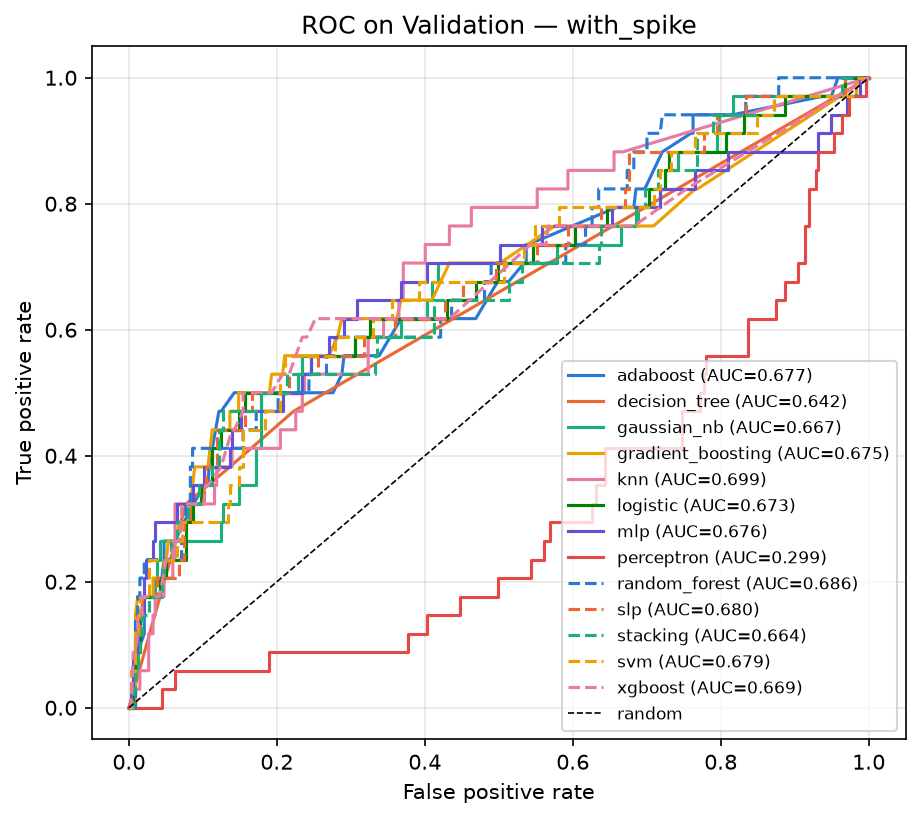

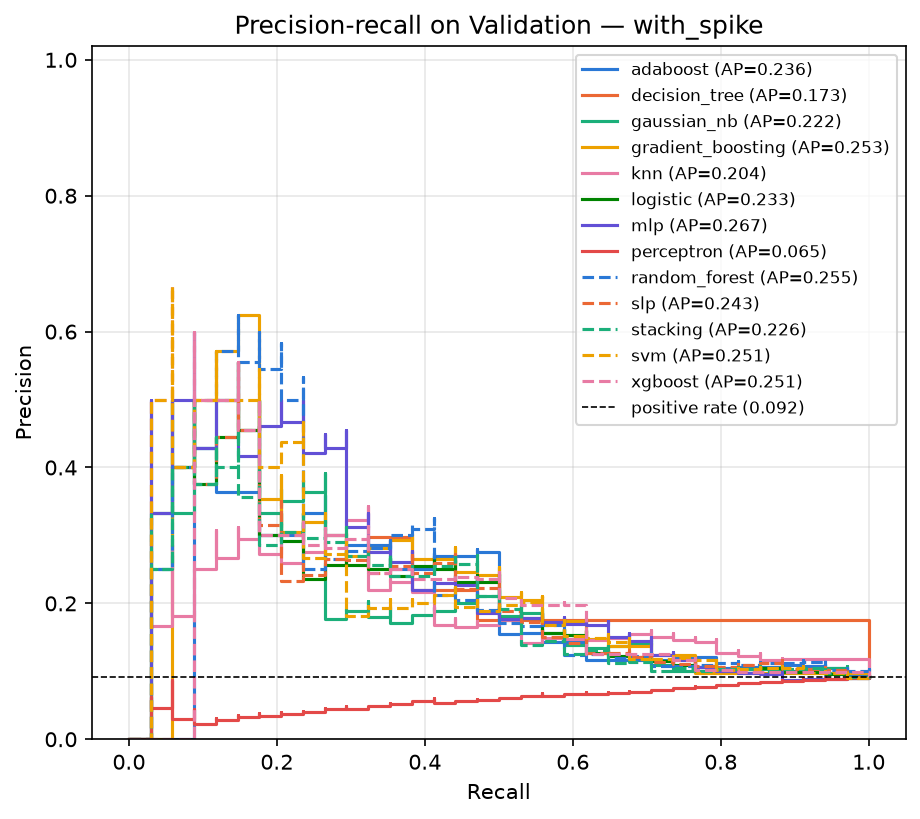

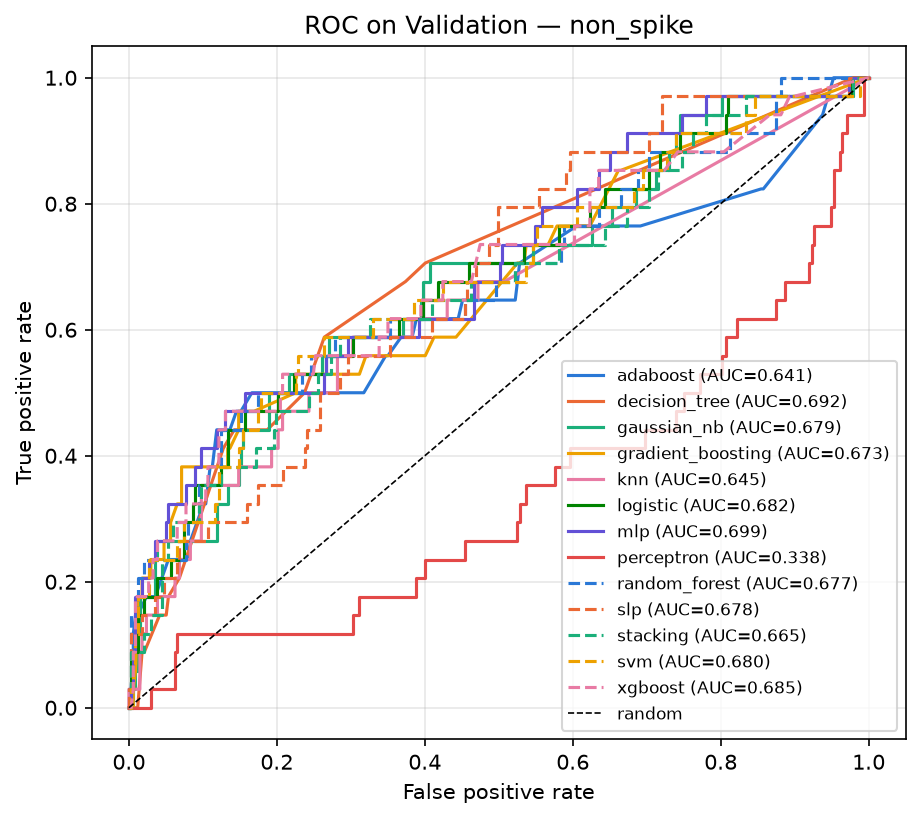

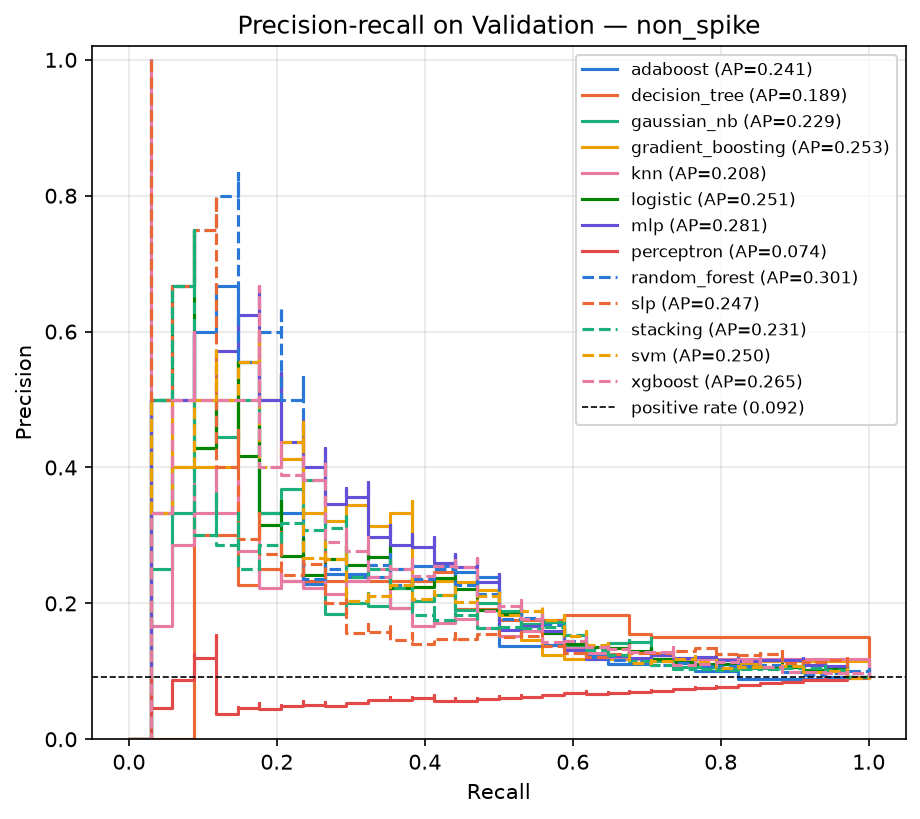

In [6]:
for variant in VARIANTS:
    show_image(FIGURE_ROOT / variant / "roc_overlay.png", width=640)
    show_image(FIGURE_ROOT / variant / "pr_overlay.png", width=640)

## 6. Confusion matrix

แต่ละกล่องคือหนึ่งโมเดล ช่องขวาล่าง (TP) คือวันผันผวนสูงที่จับได้ จากทั้งหมด 34 วัน

สังเกตว่าหลายโมเดลทำนาย positive น้อยมาก จึงจับได้เพียง 5 ถึง 11 วัน สาเหตุคือโมเดลเรียนจาก Train ที่มี positive 25% แต่ feature ของ Validation อยู่ในช่วงสงบ ความน่าจะเป็นที่โมเดลให้จึงไม่ค่อยข้าม 0.5

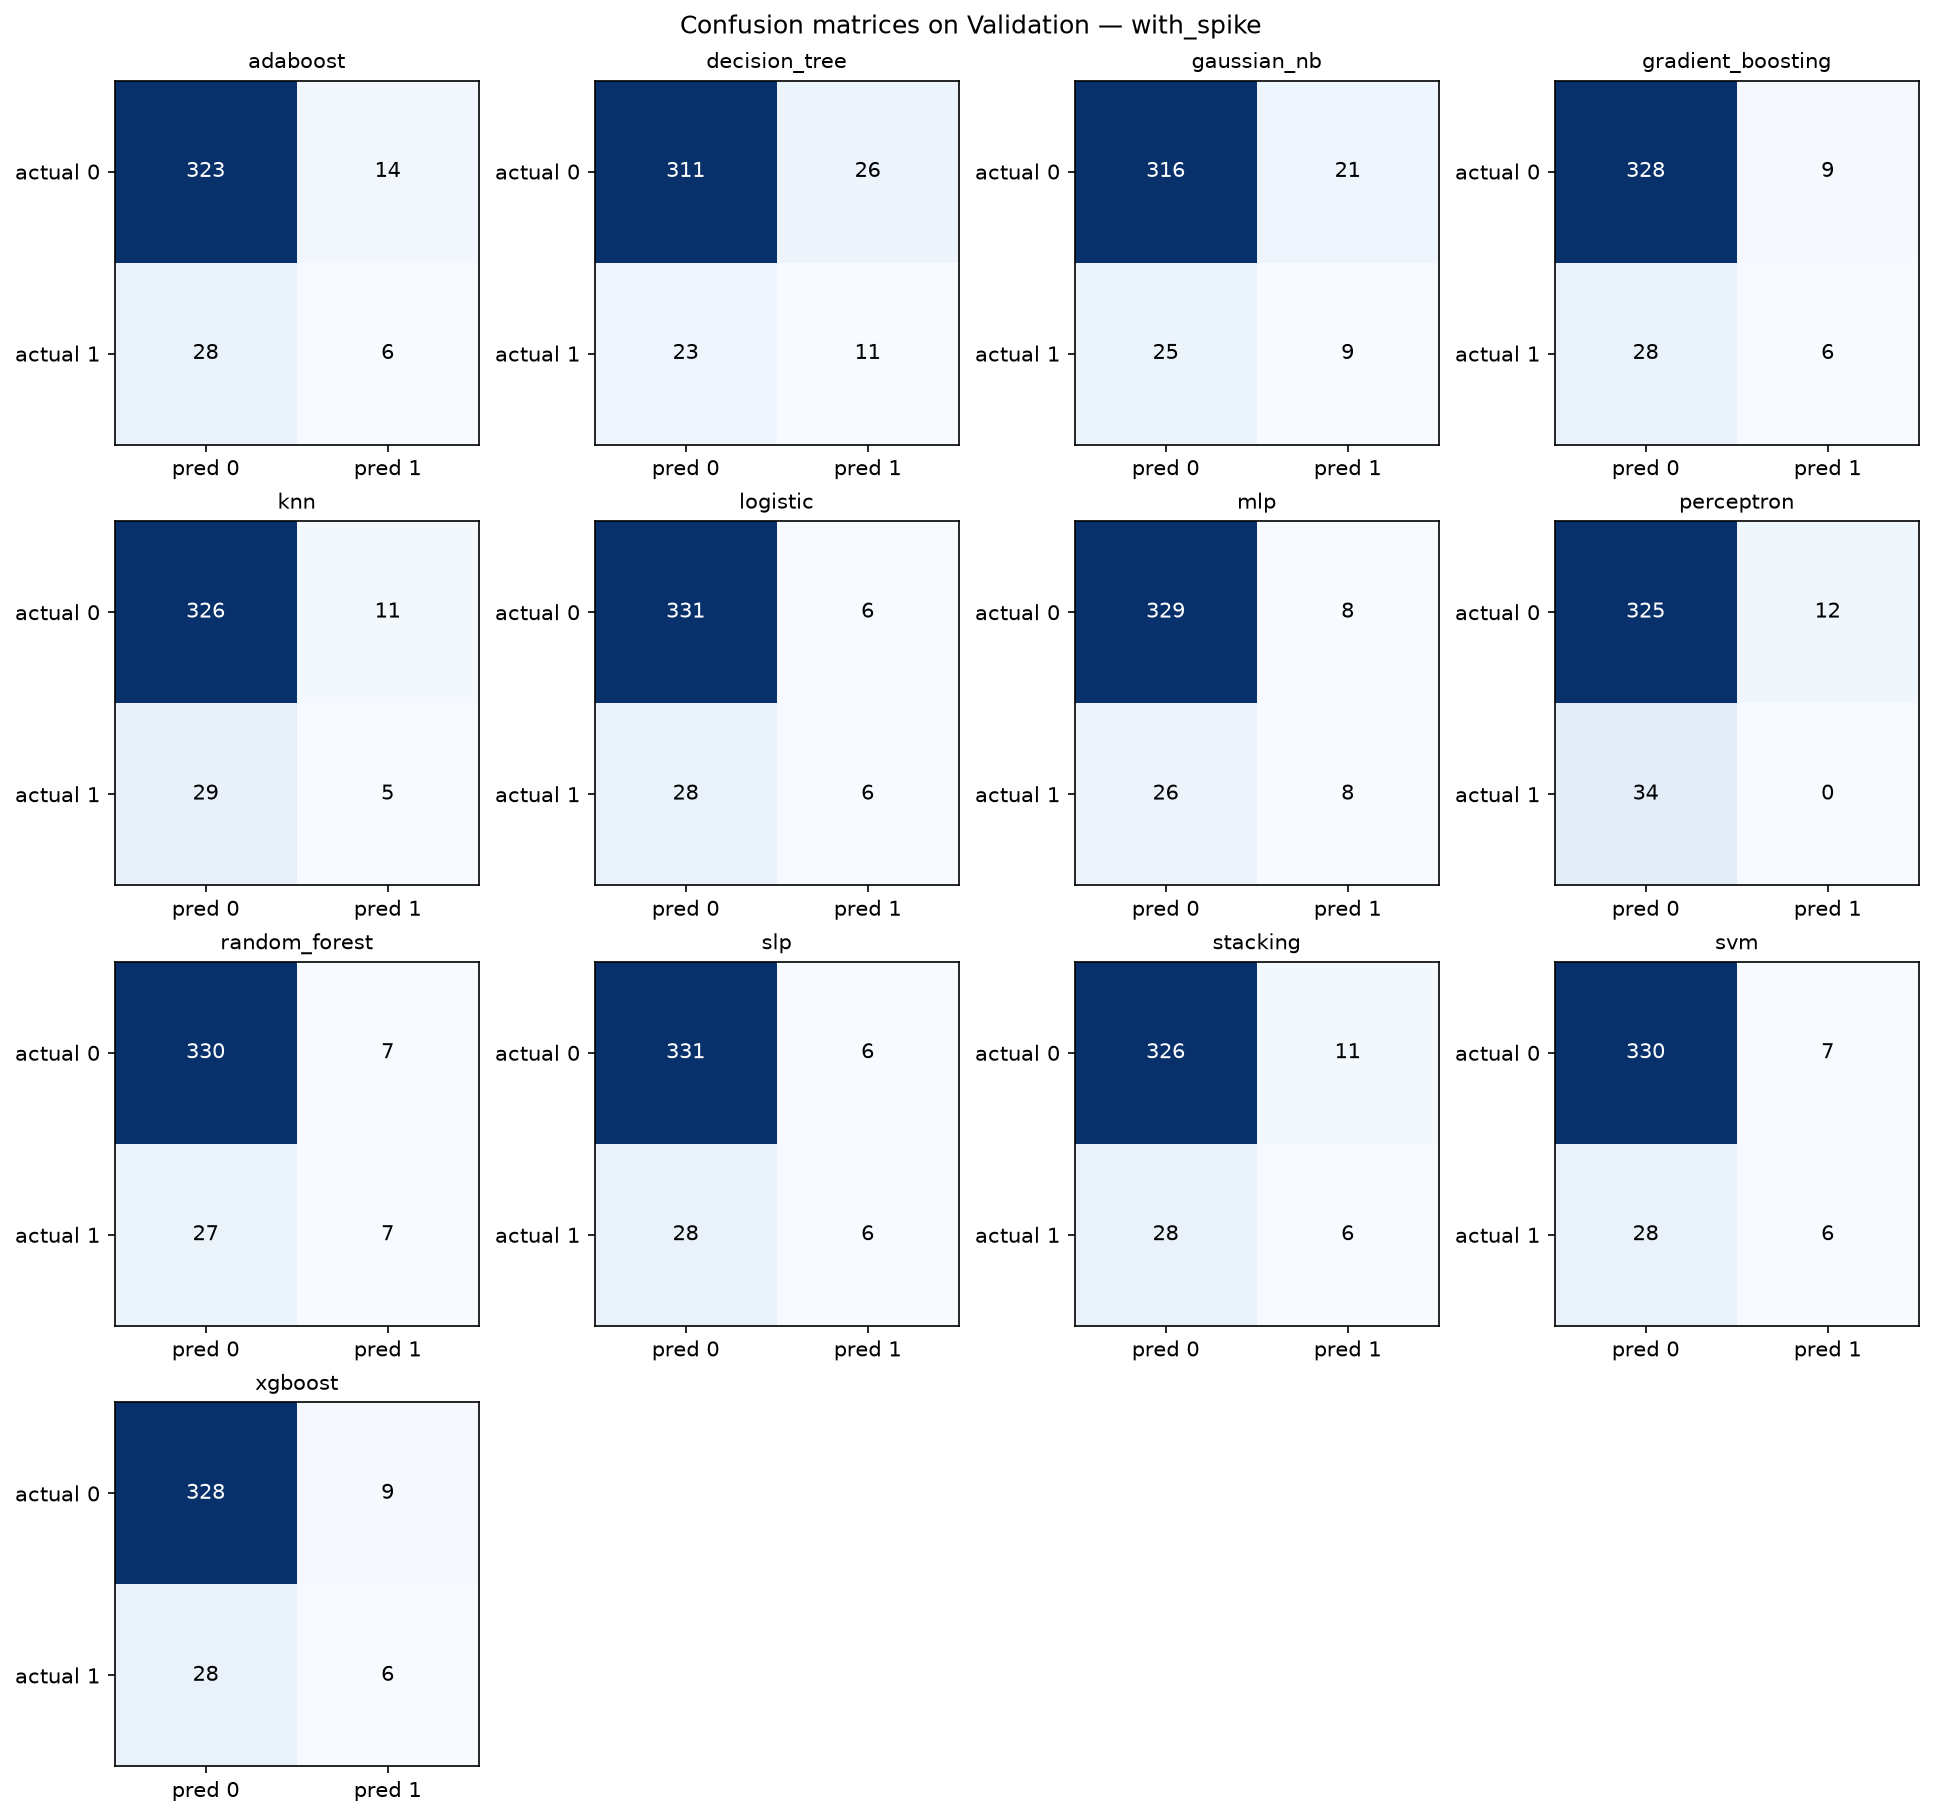

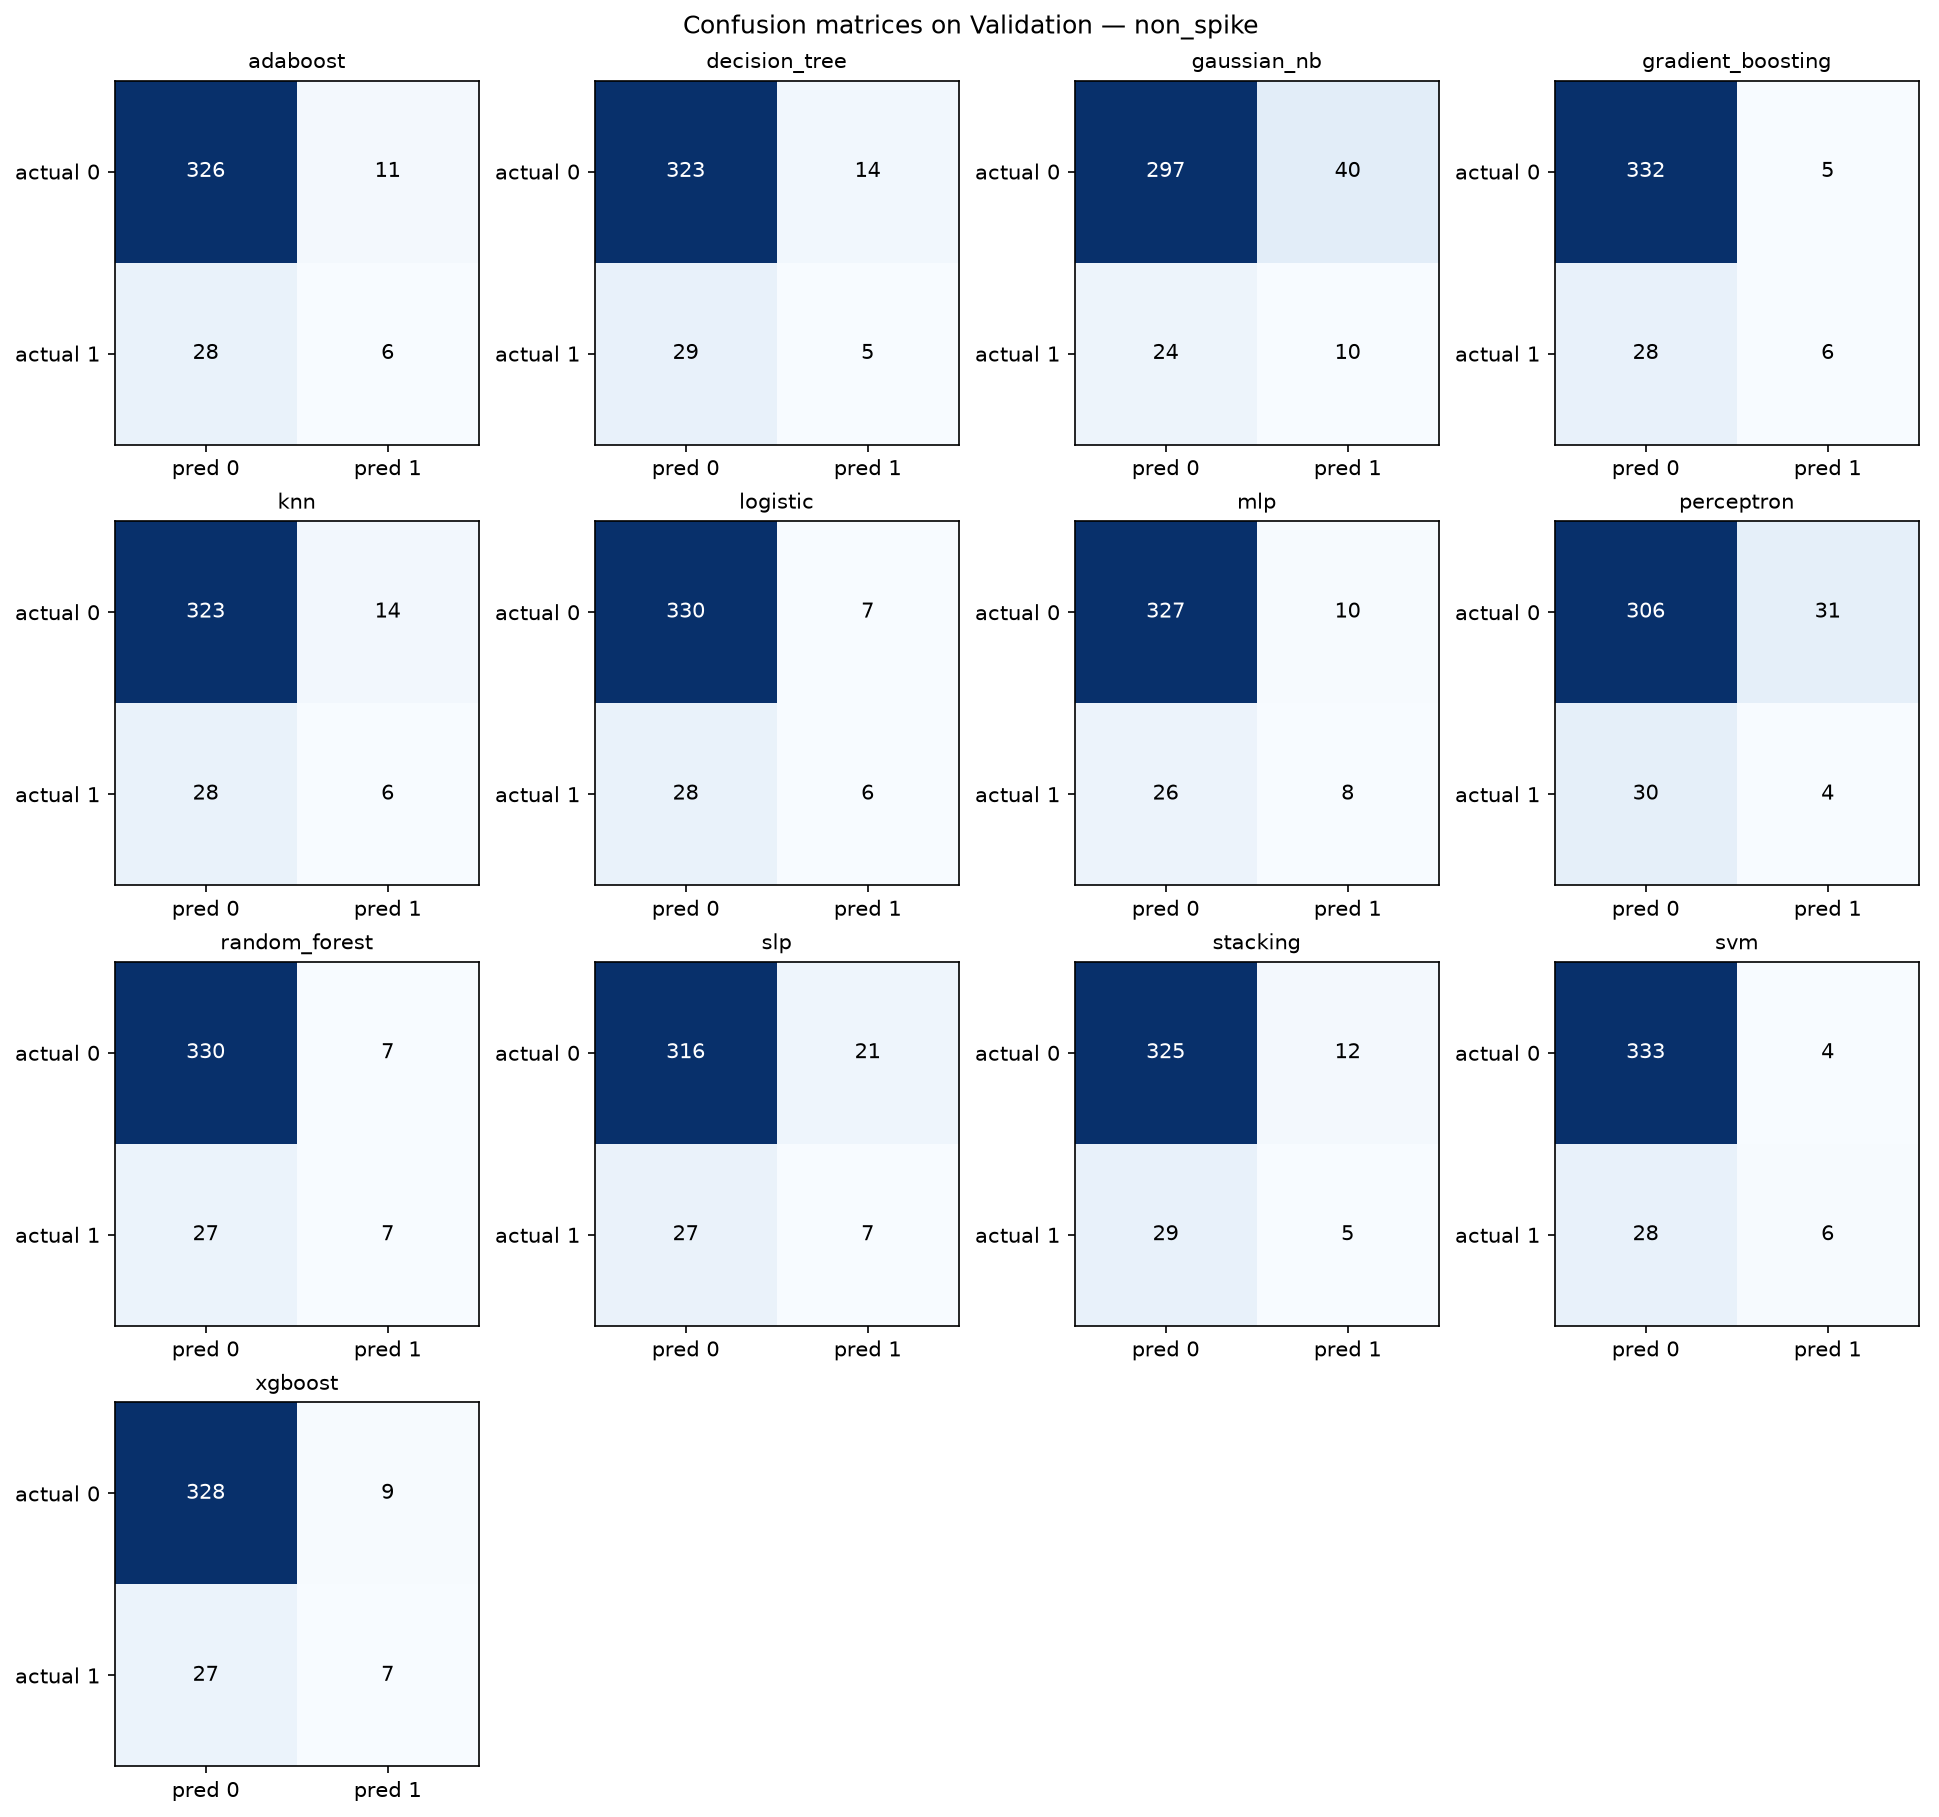

In [7]:
for variant in VARIANTS:
    show_image(FIGURE_ROOT / variant / "confusion_matrices.png", width=1000)

## 7. Performance curve

loss ระหว่างเทรนของโมเดลที่เรียนแบบวนรอบ ใช้ดูว่าโมเดลเรียนจนนิ่งหรือยัง

- เส้นที่ลดลงแล้วราบ = ลู่เข้าแล้ว
- `perceptron` แกว่งไม่ลู่เข้า เพราะข้อมูลแยกด้วยเส้นตรงไม่ได้ ซึ่งเป็นพฤติกรรมปกติของอัลกอริทึมนี้ และอธิบายคะแนนที่แย่ของมัน
- `knn`, `decision_tree`, `gaussian_nb`, `random_forest`, `stacking` ไม่มีกราฟ เพราะไม่ได้เทรนด้วยการลด loss ทีละรอบ

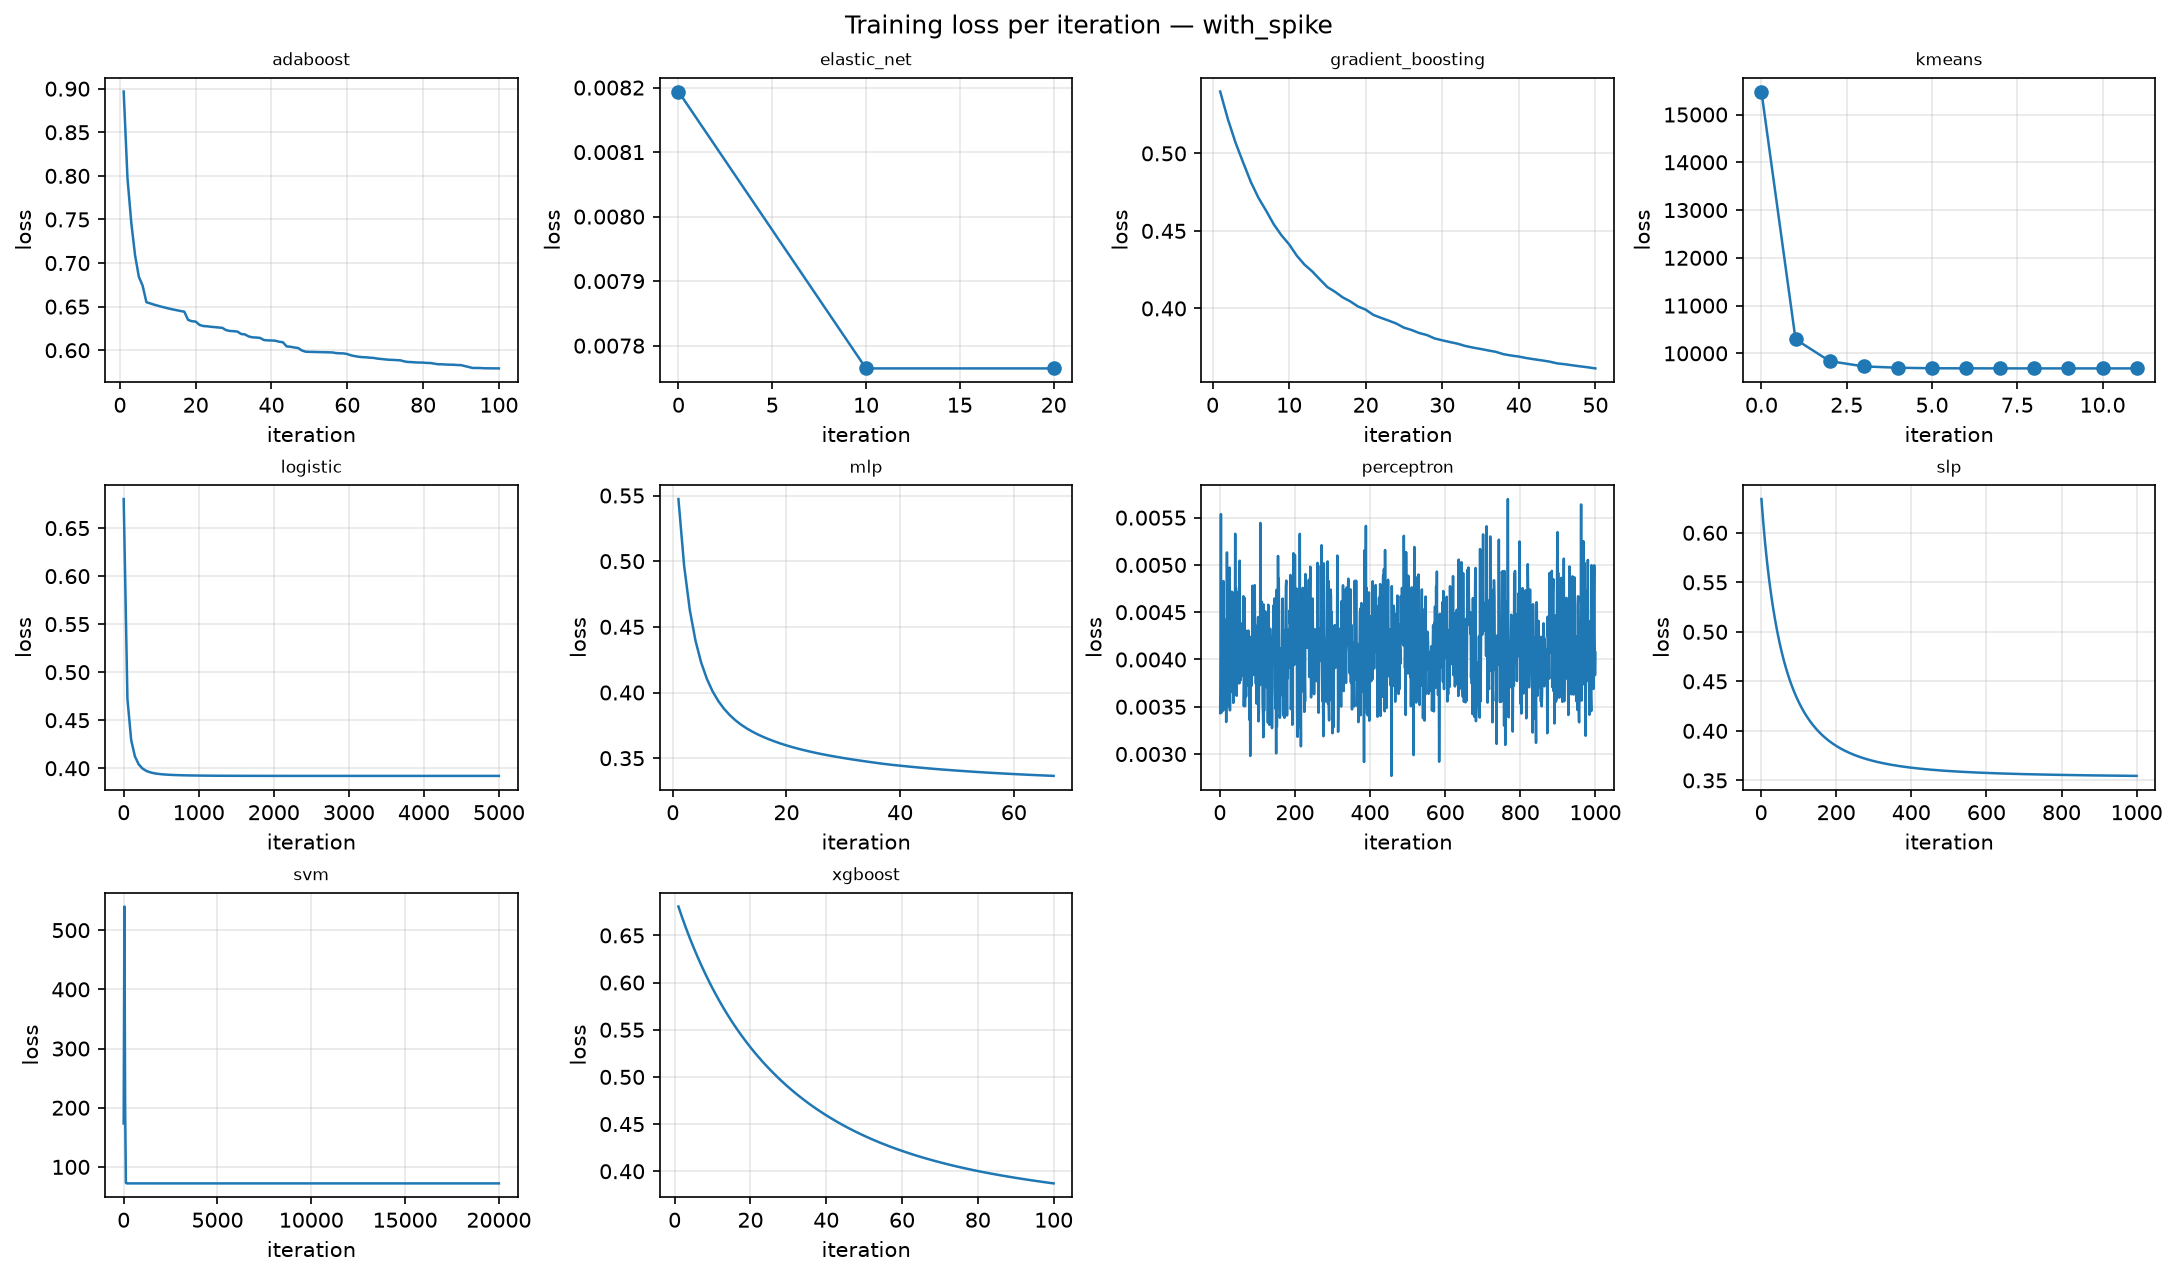

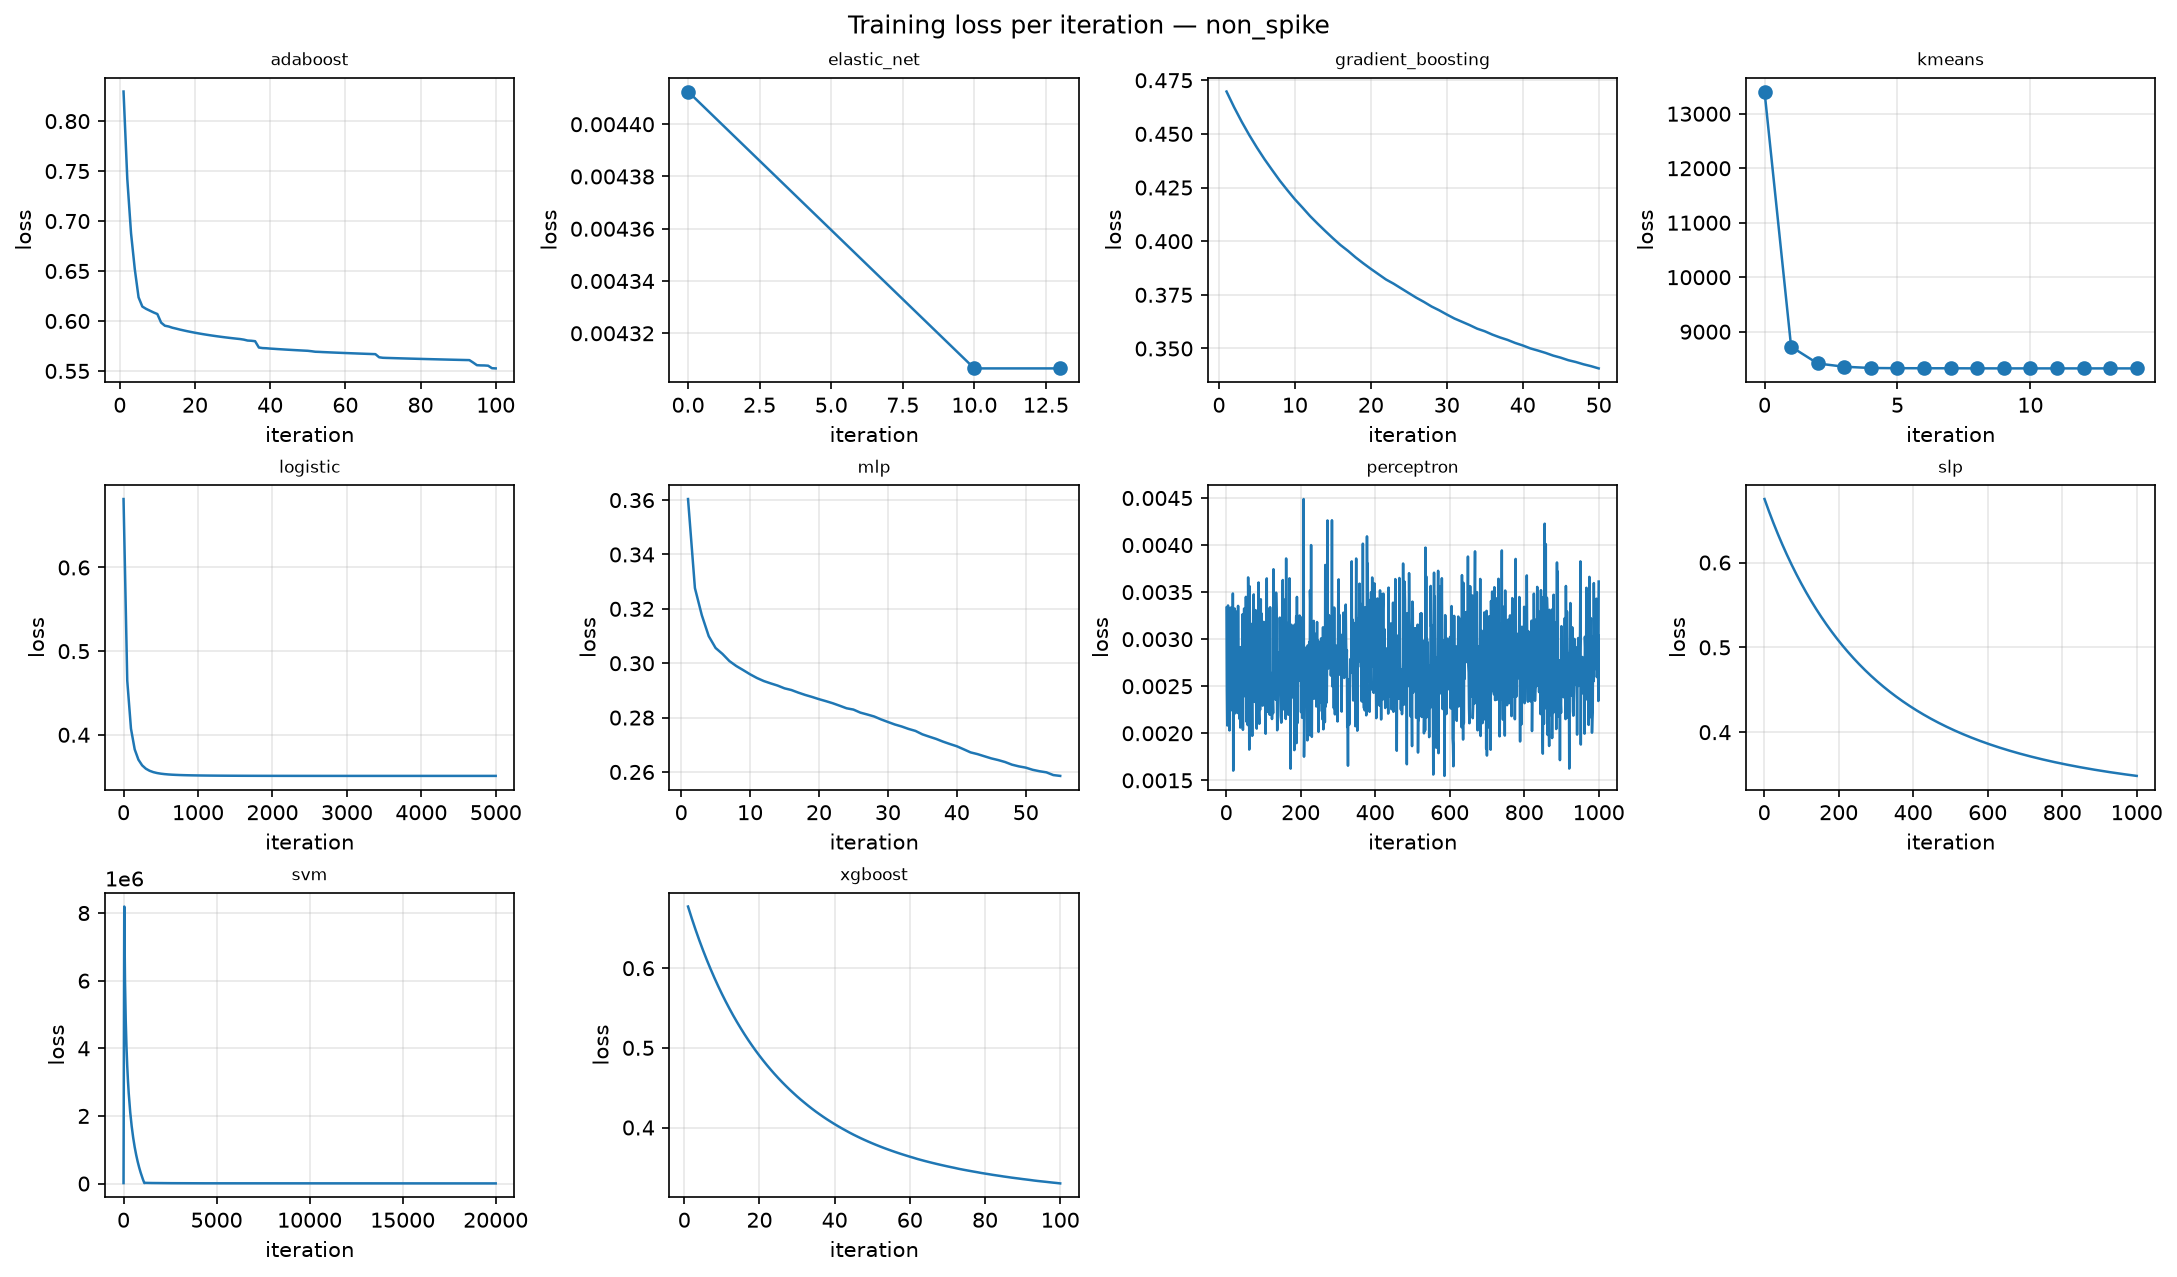

In [8]:
for variant in VARIANTS:
    show_image(FIGURE_ROOT / variant / "performance_curves.png", width=1000)

## 8. AdaBoost: โมเดลนอกห้องเรียน

AdaBoost สร้างโมเดลอ่อน (ที่นี่คือ decision stump = ต้นไม้ที่ถามคำถามเดียว) ต่อกันทีละตัว โดย **ตัวถัดไปตั้งใจแก้จุดที่ตัวก่อนหน้าทำผิด**

ขั้นตอนของแต่ละรอบ m (อัลกอริทึม SAMME):

1. เทรน stump บนข้อมูลที่แต่ละแถวมีน้ำหนัก เริ่มต้นทุกแถวหนักเท่ากัน
2. คำนวณ error แบบถ่วงน้ำหนัก ε_m
3. ให้ stump มีสิทธิ์ออกเสียง α_m = learning_rate · ln((1 − ε_m) / ε_m) ยิ่งผิดน้อยยิ่งมีเสียงมาก (สูตรของ SAMME ซึ่งเป็นสองเท่าของสูตรในตำราที่มี ½ นำหน้า การตั้งค่าที่ชนะใช้ learning_rate = 0.5)
4. เพิ่มน้ำหนักให้แถวที่ทำนายผิด เพื่อให้ stump ตัวถัดไปสนใจแถวเหล่านั้น

คำตอบสุดท้ายคือผลโหวตถ่วงน้ำหนักของ stump ทั้งหมด

**ทำไมเลือกตัวนี้:** AdaBoost ลด exponential loss ซึ่งไวต่อจุดที่ทำนายผิดหนัก ๆ จึงน่าสนใจเป็นพิเศษกับคำถามว่าช่วง spike รบกวนการเรียนรู้หรือไม่

กราฟถัดไปแสดง ε_m และ α_m ของ stump ทั้ง 100 ตัว

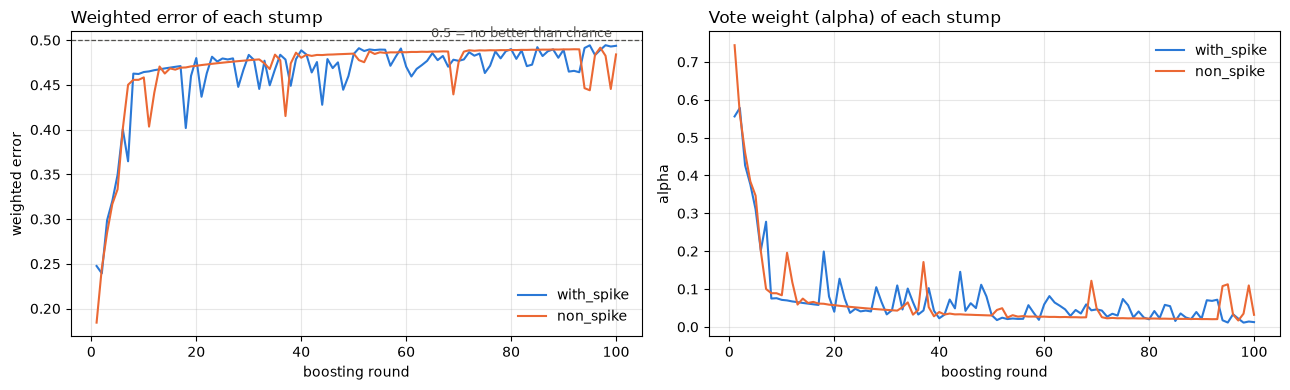

In [9]:
from src.ml.core.persist import load_npz

figure, panels = plt.subplots(1, 2, figsize=(13, 4))
for variant, color in zip(VARIANTS, ["#2a78d6", "#eb6834"]):
    arrays, _ = load_npz(read_run(OUTPUT_ROOT, variant, "adaboost").directory / "model.npz")
    rounds = np.arange(1, len(arrays["estimator_errors"]) + 1)
    panels[0].plot(rounds, arrays["estimator_errors"], color=color, linewidth=1.5, label=variant)
    panels[1].plot(rounds, arrays["estimator_weights"], color=color, linewidth=1.5, label=variant)
panels[0].axhline(0.5, color="#52514e", linestyle="--", linewidth=0.9)
panels[0].text(100, 0.5, "0.5 = no better than chance ", ha="right", va="bottom", fontsize=9, color="#52514e")
panels[0].set_title("Weighted error of each stump", loc="left")
panels[0].set_ylabel("weighted error")
panels[1].set_title("Vote weight (alpha) of each stump", loc="left")
panels[1].set_ylabel("alpha")
for axes in panels:
    axes.set_xlabel("boosting round")
    axes.grid(alpha=0.3)
    axes.legend(frameon=False)
figure.tight_layout()
plt.show()

**อ่านกราฟ:** stump รอบแรก ๆ มี error ต่ำและได้เสียงโหวตมาก รอบหลัง ๆ error ขยับเข้าใกล้ 0.5 (เส้นประ) เพราะแถวที่เหลือให้แก้คือแถวที่ยากจริง ๆ เสียงโหวตจึงเล็กลงเรื่อย ๆ

## 9. PCA กับ Random Forest และ SVM

โจทย์กำหนดให้ลอง dimensionality reduction กับสองโมเดลนี้ **PCA** หมุนแกนข้อมูลแล้วเก็บเฉพาะทิศทางที่ข้อมูลกระจายตัวมากที่สุด เช่น ย่อ feature 8 ตัวเหลือ 4 ตัว

PCA ถูก fit บน Train เท่านั้น (หลัง standardize) แล้วนำไปแปลง Validation

ตารางถัดไปแสดง AP ที่ดีที่สุดของแต่ละจำนวน component `none` คือไม่ใช้ PCA

In [10]:
pca_rows = []
for variant in VARIANTS:
    for name in ("random_forest", "svm"):
        run = read_run(OUTPUT_ROOT, variant, name)
        for item in json.loads((run.directory / "search_results.json").read_text(encoding="utf-8")):
            if item.get("status", "valid") != "valid":
                continue
            pca_rows.append({"variant": variant, "model": name,
                             "pca_components": item["pca_components"] or "none",
                             "average_precision": item["metrics"]["average_precision"]["value"]})
pca_table = (pd.DataFrame(pca_rows).groupby(["variant", "model", "pca_components"])["average_precision"].max()
             .unstack("pca_components")[["none", 2, 4, 6]])
display(pca_table.round(4))
selected = pd.DataFrame([{"variant": variant, "model": name,
                          "selected pca_components": read_run(OUTPUT_ROOT, variant, name).config["pca_components"] or "none"}
                         for variant in VARIANTS for name in ("random_forest", "svm")])
display(selected)

pca_components              none       2       4       6
variant    model                                        
non_spike  random_forest  0.3010  0.1972  0.2164  0.2038
           svm            0.2172  0.2485  0.2501  0.2452
with_spike random_forest  0.2548  0.2045  0.2235  0.2172
           svm            0.2151  0.2458  0.2514  0.2475

,variant,model,selected pca_components
0,with_spike,random_forest,none
1,with_spike,svm,4
2,non_spike,random_forest,none
3,non_spike,svm,4


## 10. Clustering: k-Means และ Agglomerative

Clustering เป็น **unsupervised learning**: โมเดลไม่เห็น label ตอนเทรน มันแค่จัดวันที่มี feature คล้ายกันไว้กลุ่มเดียวกัน

- **k-Means**: เลือกจุดศูนย์กลาง k จุด แล้วสลับระหว่าง "จัดแต่ละวันเข้าศูนย์กลางที่ใกล้สุด" กับ "ย้ายศูนย์กลางไปที่ค่าเฉลี่ยของกลุ่ม" จนนิ่ง
- **Agglomerative**: เริ่มจากทุกวันเป็นกลุ่มของตัวเอง แล้วรวมสองกลุ่มที่ใกล้กันที่สุดซ้ำ ๆ จนเหลือ k กลุ่ม วิธีนี้ไม่มีขั้นตอนทำนายข้อมูลใหม่โดยธรรมชาติ เราจึงจัดวันใน Validation เข้ากลุ่มที่จุดศูนย์กลางใกล้ที่สุด

**Silhouette** วัดว่ากลุ่มแยกจากกันชัดแค่ไหน ค่าอยู่ระหว่าง −1 ถึง 1 ยิ่งสูงยิ่งแยกชัด

ตาราง crosstab ถัดไปตอบคำถามที่น่าสนใจกว่า: กลุ่มที่ได้ (ซึ่งไม่เคยเห็น label) ตรงกับวันผันผวนสูงแค่ไหน

In [11]:
for variant in VARIANTS:
    show_markdown(REPORT_ROOT / variant / "leaderboard_clustering.md")
    for name in ("kmeans", "agglomerative"):
        run = read_run(OUTPUT_ROOT, variant, name)
        cross = pd.crosstab(pd.Series(run.prediction.astype(int), name=f"{name} cluster"),
                            pd.Series(run.target.astype(int), name="high volatility (actual)"), margins=True)
        cross["positive rate"] = (cross[1] / cross["All"]).round(3)
        display(cross)

### Validation clustering metrics — with_spike

| model | variant | k | silhouette | inertia | cluster_sizes |
| --- | --- | --- | --- | --- | --- |
| agglomerative | with_spike | 2 | 0.3602 | 1070.4207 | {"0": 293, "1": 78} |
| kmeans | with_spike | 2 | 0.3666 | 1075.1372 | {"0": 73, "1": 298} |

> silhouette/inertia คำนวณบน Validation ไม่มีช่วงความเชื่อมั่น


high volatility (actual),0,1,All,positive rate
kmeans cluster,,,,
0,57,16,73,0.219
1,280,18,298,0.060
All,337,34,371,0.092


high volatility (actual),0,1,All,positive rate
agglomerative cluster,,,,
0,275,18,293,0.061
1,62,16,78,0.205
All,337,34,371,0.092


### Validation clustering metrics — non_spike

| model | variant | k | silhouette | inertia | cluster_sizes |
| --- | --- | --- | --- | --- | --- |
| agglomerative | non_spike | 2 | 0.4642 | 1844.8884 | {"0": 359, "1": 12} |
| kmeans | non_spike | 2 | 0.3298 | 1448.9259 | {"0": 267, "1": 104} |

> silhouette/inertia คำนวณบน Validation ไม่มีช่วงความเชื่อมั่น


high volatility (actual),0,1,All,positive rate
kmeans cluster,,,,
0,251,16,267,0.060
1,86,18,104,0.173
All,337,34,371,0.092


high volatility (actual),0,1,All,positive rate
agglomerative cluster,,,,
0,331,28,359,0.078
1,6,6,12,0.500
All,337,34,371,0.092


**อ่าน crosstab:** ถ้ากลุ่มหนึ่งมี `positive rate` สูงกว่าอีกกลุ่มชัดเจน แปลว่า feature เพียงอย่างเดียวก็แยกสภาพตลาดได้ระดับหนึ่งโดยไม่ต้องมี label เทียบกับ positive rate รวม 0.092

## 11. Save → load → ทำนายซ้ำ

เหมือนเล่ม 03: โหลด `model.npz` และ `preprocessor.npz` ของทุก run ขึ้นมาใหม่ ทำนาย Validation อีกรอบ แล้วเทียบกับค่าที่บันทึกไว้ ครอบคลุม classifier 13 ตัวและ clustering 2 ตัว ทั้งสอง variant รวม 30 run

In [12]:
checks = []
for variant in VARIANTS:
    validation = data[variant].validation
    for run in read_runs(OUTPUT_ROOT, variant):
        if run.task == "regression":
            continue
        model, transform = load_model(run.directory)
        _, prediction, _ = evaluate(model, transform(validation.X), validation.y_regression,
                                    validation.y_classification, run.task)
        stored = json.loads((run.directory / "load_verification.json").read_text(encoding="utf-8"))
        checks.append({"variant": variant, "task": run.task, "model": run.name, "stored_passed": stored["passed"],
                       "reproduced_here": bool(np.array_equal(prediction, run.prediction))})
checks = pd.DataFrame(checks)
with pd.option_context("display.max_rows", 40):
    display(checks)
print(len(checks), "runs checked; all reproduced:", bool(checks["reproduced_here"].all()))
assert checks["stored_passed"].all() and checks["reproduced_here"].all()

,variant,task,model,stored_passed,reproduced_here
0,with_spike,classification,adaboost,True,True
1,with_spike,clustering,agglomerative,True,True
2,with_spike,classification,decision_tree,True,True
3,with_spike,classification,gaussian_nb,True,True
4,with_spike,classification,gradient_boosting,True,True
5,with_spike,clustering,kmeans,True,True
6,with_spike,classification,knn,True,True
7,with_spike,classification,logistic,True,True
8,with_spike,classification,mlp,True,True
9,with_spike,classification,perceptron,True,True


30 runs checked; all reproduced: True


## 12. เทียบกับ library (parity demo)

โมเดลของเรา **โหลดจากไฟล์** ส่วนโมเดลของ scikit-learn ถูก fit ตรงนี้บน Train ชุดเดียวกันด้วยการตั้งค่าเดียวกัน แล้วเทียบคำทำนายบน Validation

เราเลือกสามตัวที่ต่างกันทางวิธีคิด: `adaboost` (โมเดลนอกห้องเรียน), `knn` (อิงระยะทาง) และ `gaussian_nb` (อิงความน่าจะเป็น)

หมายเหตุ: โมเดลที่มีการสุ่มต้องใช้ตัวสุ่มชนิดเดียวกับ scikit-learn (`numpy.random.RandomState`) จึงจะได้ผลตรงกัน ผลเทียบครบทั้ง 19 โมเดลอยู่ใน test ของแต่ละโมเดลใต้ `tests/ml/`

In [13]:
PARITY_MODELS = ['adaboost', 'knn', 'gaussian_nb']


def parity_demo(name, variant="with_spike"):
    """Scratch model reloaded from disk vs the library reference fitted on the same inputs."""
    data = load(variant)
    run = read_run(OUTPUT_ROOT, variant, name)
    scratch, transform = load_model(run.directory)
    train_X, validation_X = transform(data.train.X), transform(data.validation.X)
    y = data.train.y_regression if run.task == "regression" else data.train.y_classification
    reference = scratch.reference().fit(train_X, y)
    result = assert_parity(scratch, reference, validation_X, task=run.task)
    gap = np.abs(np.asarray(scratch.predict(validation_X), dtype=float)
                 - np.asarray(reference.predict(validation_X), dtype=float)).max()
    return {"model": name, "reference": type(reference).__name__, "rows": result["n_samples"],
            "max_abs_diff": float(gap), "rtol": result["rtol"], "passed": result["passed"]}


parity_rows = [parity_demo(name) for name in PARITY_MODELS]

display(pd.DataFrame(parity_rows))

,model,reference,rows,max_abs_diff,rtol,passed
0,adaboost,AdaBoostClassifier,371,0.0,0.00001,True
1,knn,KNeighborsClassifier,371,0.0,0.00001,True
2,gaussian_nb,GaussianNB,371,0.0,0.00001,True


## 13. ฟีเจอร์ไหนสำคัญ

**วิธีวัด (block-permutation importance):** สลับลำดับค่าของ feature หนึ่งตัวบน Validation เป็นก้อน 20 วัน แล้วดูว่า AP ลดลงเท่าไร ทำซ้ำ 30 รอบ

- สีเข้ม = สลับแล้ว AP ลดลงมาก = โมเดลพึ่ง feature นั้นมาก
- ค่าติดลบ = สลับแล้ว AP ดีขึ้น = feature นั้นไม่ช่วยบน Validation ชุดนี้
- feature ที่สัมพันธ์กันจะแบ่งความสำคัญกัน และ AP ตั้งอยู่บนวัน positive 34 วัน จึงต้องอ่านคู่กับ `std` เสมอ

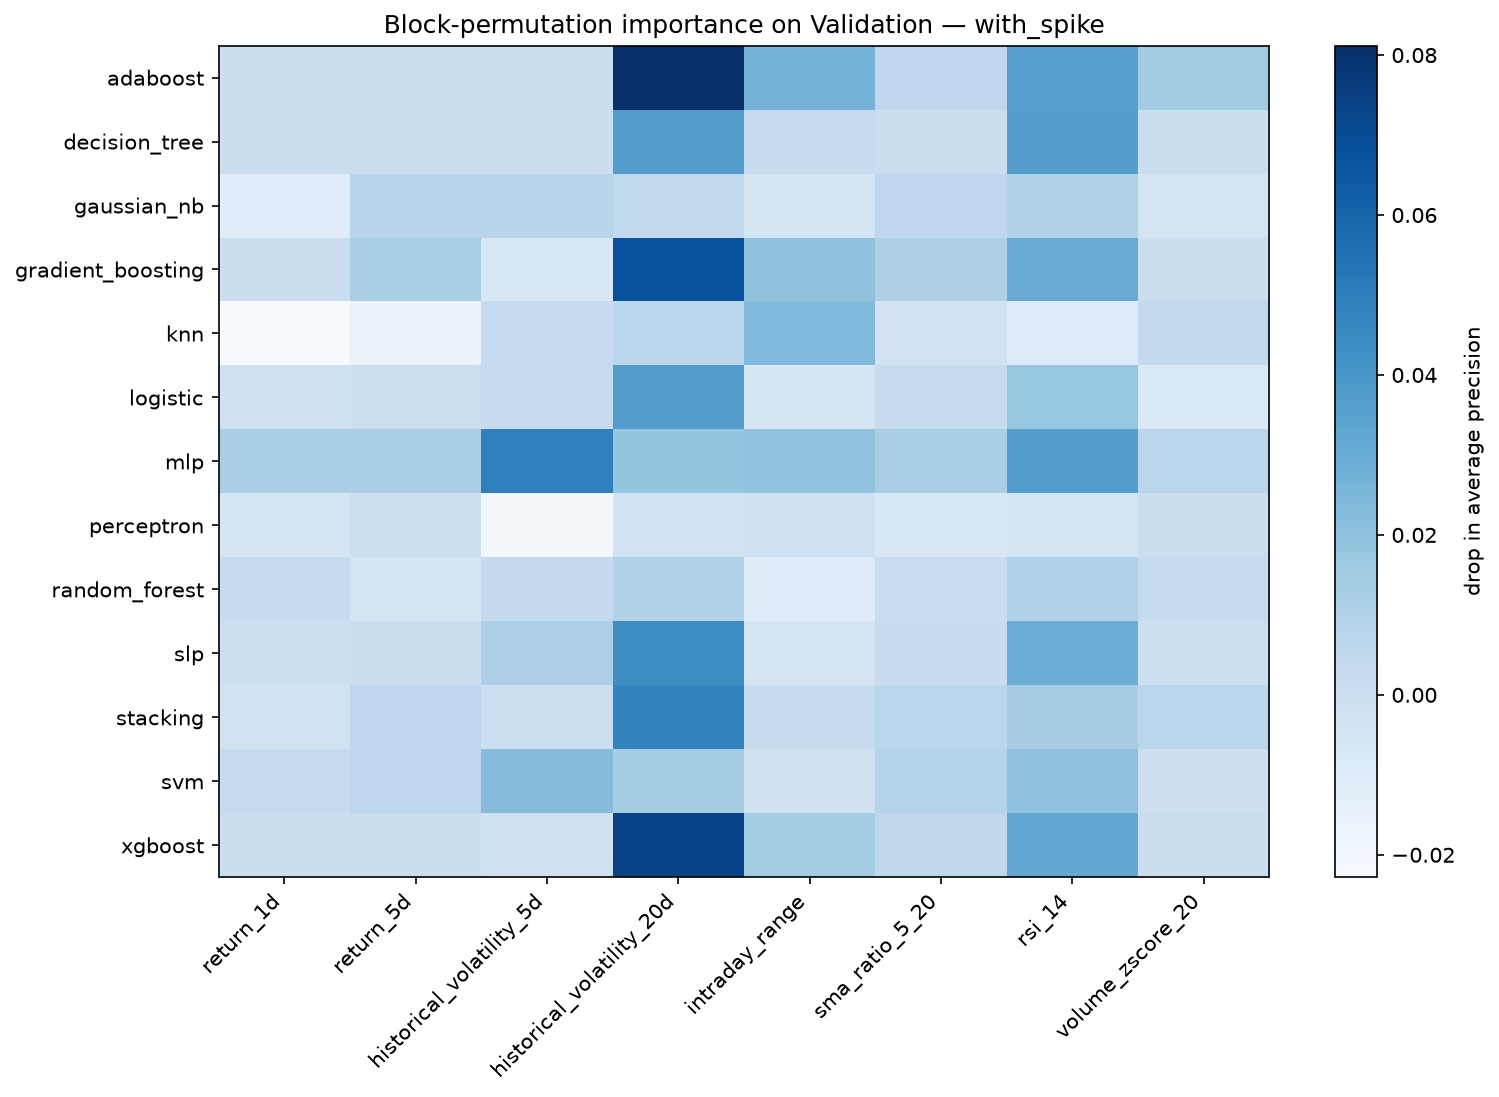

with_spike


,most important,second,third
model,,,
adaboost,historical_volatility_20d (+0.081 ± 0.056),rsi_14 (+0.036 ± 0.019),intraday_range (+0.027 ± 0.027)
decision_tree,historical_volatility_20d (+0.037 ± 0.050),rsi_14 (+0.036 ± 0.021),intraday_range (+0.002 ± 0.008)
gaussian_nb,rsi_14 (+0.010 ± 0.020),return_5d (+0.008 ± 0.010),historical_volatility_5d (+0.007 ± 0.011)
gradient_boosting,historical_volatility_20d (+0.068 ± 0.059),rsi_14 (+0.030 ± 0.019),intraday_range (+0.020 ± 0.021)
knn,intraday_range (+0.023 ± 0.020),historical_volatility_20d (+0.006 ± 0.029),volume_zscore_20 (+0.004 ± 0.014)
logistic,historical_volatility_20d (+0.037 ± 0.050),rsi_14 (+0.018 ± 0.022),sma_ratio_5_20 (+0.003 ± 0.011)
mlp,historical_volatility_5d (+0.049 ± 0.040),rsi_14 (+0.036 ± 0.023),intraday_range (+0.019 ± 0.032)
perceptron,volume_zscore_20 (+0.000 ± 0.002),return_5d (-0.000 ± 0.002),intraday_range (-0.001 ± 0.002)
random_forest,rsi_14 (+0.010 ± 0.016),historical_volatility_20d (+0.010 ± 0.033),historical_volatility_5d (+0.003 ± 0.026)


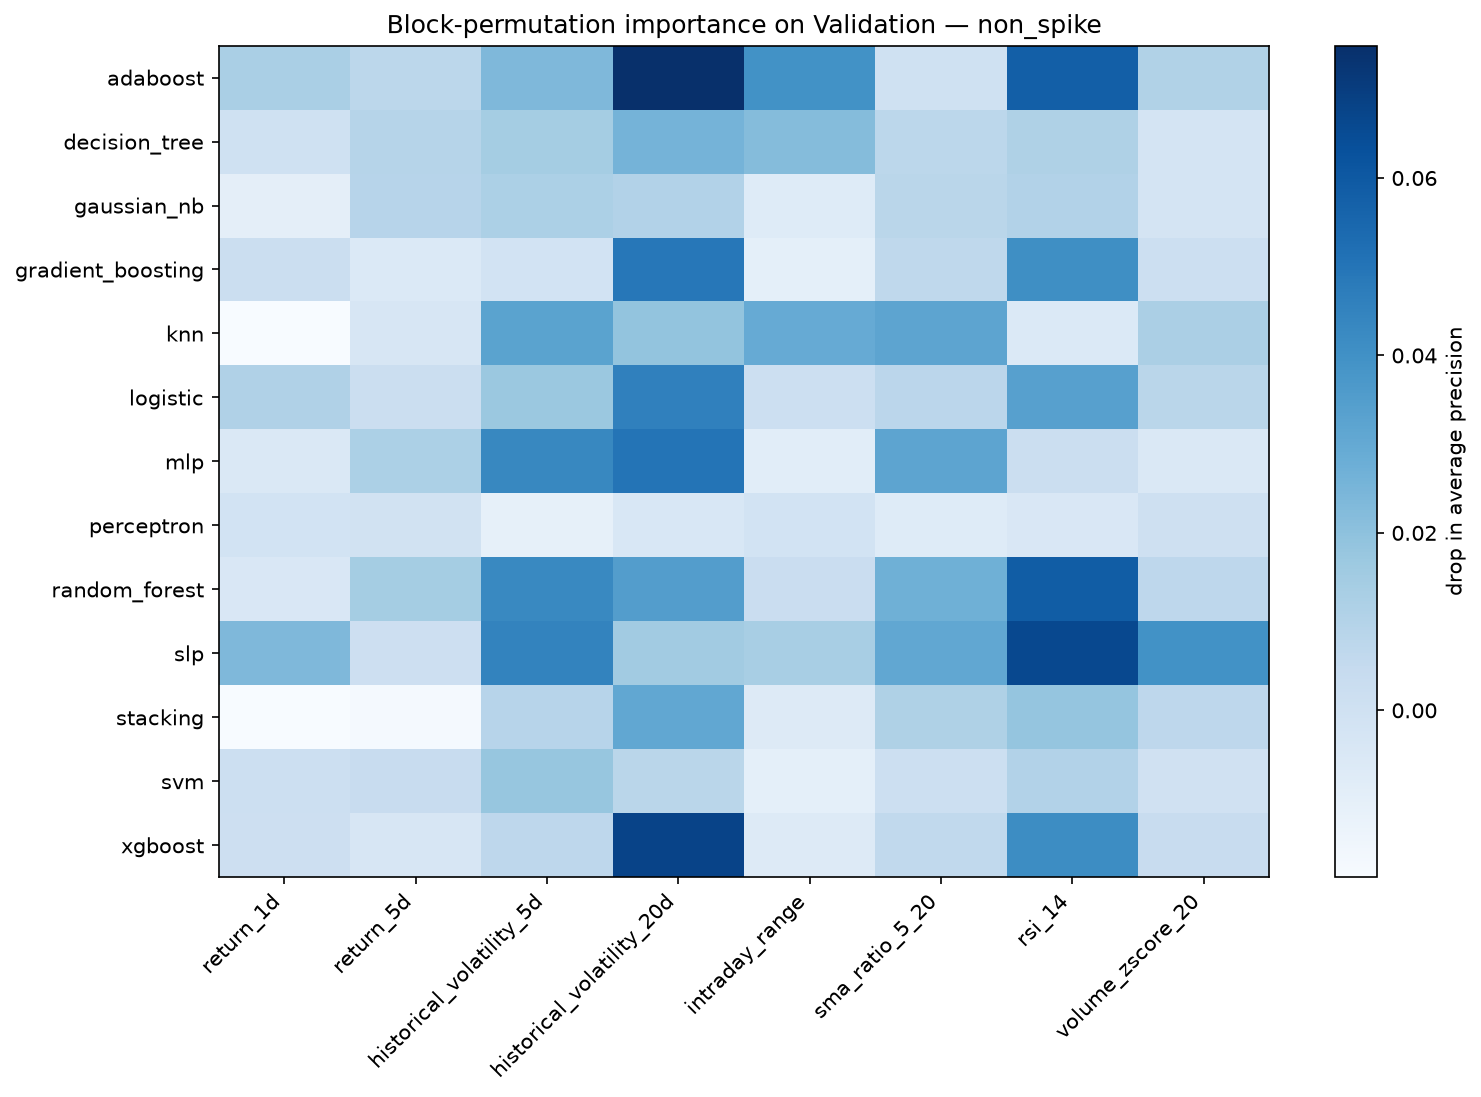

non_spike


,most important,second,third
model,,,
adaboost,historical_volatility_20d (+0.075 ± 0.062),rsi_14 (+0.058 ± 0.029),intraday_range (+0.039 ± 0.035)
decision_tree,historical_volatility_20d (+0.026 ± 0.026),intraday_range (+0.022 ± 0.013),historical_volatility_5d (+0.014 ± 0.007)
gaussian_nb,historical_volatility_5d (+0.012 ± 0.017),rsi_14 (+0.010 ± 0.016),historical_volatility_20d (+0.010 ± 0.014)
gradient_boosting,historical_volatility_20d (+0.049 ± 0.057),rsi_14 (+0.041 ± 0.027),sma_ratio_5_20 (+0.006 ± 0.019)
knn,historical_volatility_5d (+0.032 ± 0.023),sma_ratio_5_20 (+0.032 ± 0.026),intraday_range (+0.029 ± 0.024)
logistic,historical_volatility_20d (+0.046 ± 0.055),rsi_14 (+0.034 ± 0.026),historical_volatility_5d (+0.017 ± 0.017)
mlp,historical_volatility_20d (+0.050 ± 0.046),historical_volatility_5d (+0.043 ± 0.036),sma_ratio_5_20 (+0.032 ± 0.018)
perceptron,volume_zscore_20 (+0.001 ± 0.009),return_5d (-0.001 ± 0.006),return_1d (-0.001 ± 0.003)
random_forest,rsi_14 (+0.059 ± 0.028),historical_volatility_5d (+0.043 ± 0.032),historical_volatility_20d (+0.035 ± 0.028)


In [14]:
for variant in VARIANTS:
    show_image(FIGURE_ROOT / variant / "feature_importance.png", width=820)
    importance = table(REPORT_ROOT / variant / "feature_importance.csv").query("task == 'classification'")
    top = (importance.sort_values("importance_mean", ascending=False).groupby("model").head(3)
           .assign(rank=lambda frame: frame.groupby("model").cumcount() + 1,
                   value=lambda frame: frame["feature"] + " (" + frame["importance_mean"].map("{:+.3f}".format)
                   + " ± " + frame["importance_std"].map("{:.3f}".format) + ")")
           .pivot(index="model", columns="rank", values="value"))
    top.columns = ["most important", "second", "third"]
    print(variant)
    display(top)

## 14. Robustness: walk-forward ภายใน Train

Validation มีวัน positive แค่ 34 วันจากสภาพตลาดแบบเดียว เราจึงตรวจซ้ำอีกทางว่าอันดับของโมเดลคงที่ข้ามช่วงเวลาหรือไม่

**วิธีทำ:** แบ่ง Train เป็นช่วงตามเวลา เทรนด้วยข้อมูลช่วงต้น แล้วทดสอบกับช่วงถัดไป ขยายหน้าต่างไปเรื่อย ๆ 4 รอบ (เว้น purge gap ระหว่างช่วงเทรนกับช่วงทดสอบ) ใช้การตั้งค่าที่ชนะบน Validation ตัวเดิม **ไม่มีการเลือกโมเดลหรือปรับค่าใหม่** จากผลนี้

**ข้อดี:** ช่วงทดสอบรวมกันมีวัน positive หลายร้อยวัน และครอบคลุมหลายสภาพตลาดรวมถึงปี 2020

**ข้อจำกัด:** โมเดลในตารางนี้เทรนด้วยข้อมูลน้อยกว่าโมเดลจริง จึงเป็นหลักฐานเสริมเรื่องความเสถียร ไม่ใช่คะแนนของโมเดลที่ส่ง

**หมายเหตุเรื่อง `stacking`:** ช่อง fold 0 ว่าง เพราะ 275 วันแรกของ Train (ก.ย. 2016 ถึง ต.ค. 2017) ไม่มีวันผันผวนสูงเลย `stacking` ต้องแบ่งข้อมูลภายในอีกชั้นเพื่อเทรน meta-model จึงเทรนบนประวัติที่สั้นที่สุดไม่ได้ แถว pooled ของมันจึงมาจาก 3 fold และเทียบกับตัวอื่นตรง ๆ ไม่ได้

In [15]:
for variant in VARIANTS:
    walk = table(REPORT_ROOT / variant / "walk_forward.csv")
    folds = walk[walk["fold"].astype(str) != "pooled"].pivot(index="model", columns="fold", values="average_precision")
    folds.columns = [f"fold {column} AP" for column in folds.columns]
    pooled = walk[walk["fold"].astype(str) == "pooled"].set_index("model")
    summary = folds.join(pooled[["positives", "average_precision", "average_precision_low", "average_precision_high"]])
    summary = summary.rename(columns={"average_precision": "pooled AP", "average_precision_low": "pooled low",
                                      "average_precision_high": "pooled high"})
    print(variant)
    display(summary.sort_values("pooled AP", ascending=False).round(4))

with_spike


,fold 0 AP,fold 1 AP,fold 2 AP,fold 3 AP,positives,pooled AP,pooled low,pooled high
model,,,,,,,,
gaussian_nb,0.8282,0.6361,0.7775,0.4436,353,0.7124,0.5717,0.8151
gradient_boosting,0.8117,0.5722,0.8168,0.5522,353,0.7120,0.5857,0.8059
logistic,0.8173,0.6103,0.7847,0.4511,353,0.7030,0.5548,0.8083
random_forest,0.8079,0.6003,0.8018,0.5108,353,0.6833,0.5582,0.7797
svm,0.7946,0.6118,0.7839,0.4556,353,0.6718,0.5280,0.7842
slp,0.7946,0.5278,0.7658,0.4313,353,0.6717,0.5205,0.7813
adaboost,0.7998,0.5650,0.8330,0.4458,353,0.6708,0.5383,0.7772
xgboost,0.7604,0.5602,0.8042,0.5628,353,0.6690,0.5514,0.7645
mlp,0.7662,0.5310,0.8070,0.4385,353,0.6663,0.5203,0.7738


non_spike


,fold 0 AP,fold 1 AP,fold 2 AP,fold 3 AP,positives,pooled AP,pooled low,pooled high
model,,,,,,,,
stacking,NaN,0.5782,0.6482,0.4522,191,0.5666,0.4375,0.6853
gaussian_nb,0.3405,0.5518,0.6727,0.4235,211,0.5578,0.4271,0.6590
random_forest,0.3386,0.5408,0.6765,0.4222,211,0.5425,0.4098,0.6590
knn,0.3376,0.5442,0.7030,0.4203,211,0.5417,0.3957,0.6603
logistic,0.2622,0.4996,0.6770,0.4000,211,0.5399,0.4019,0.6477
xgboost,0.3175,0.5037,0.7020,0.3927,211,0.5238,0.3871,0.6469
gradient_boosting,0.3800,0.4836,0.6528,0.4287,211,0.5234,0.3883,0.6430
slp,0.3711,0.4578,0.6540,0.3513,211,0.5028,0.3635,0.6237
adaboost,0.2976,0.4025,0.6531,0.4130,211,0.5020,0.3604,0.6220


**อ่านตาราง:** ดูสองอย่าง (1) คะแนนของโมเดลเดียวกันต่างกันมากแค่ไหนระหว่าง fold ซึ่งบอกว่าสภาพตลาดมีผลมากกว่าชนิดของโมเดลหรือไม่ และ (2) ช่วง `pooled low` ถึง `pooled high` ของแต่ละโมเดลซ้อนทับกันหรือไม่ notebook 05 นำอันดับนี้ไปเทียบกับอันดับบน Validation

## 15. สรุป

**ข้อค้นพบ**

1. บน Validation classifier ส่วนใหญ่ได้ AP ราว 0.20 ถึง 0.30 สูงกว่าการเดาสุ่ม (0.092) แต่ช่วงความเชื่อมั่นกว้างจนแยกอันดับระหว่างโมเดลไม่ได้
2. `baseline_persistence` ซึ่งไม่ได้เทรนอะไรเลย ทำได้ใกล้เคียงโมเดลส่วนใหญ่ และมี ROC-AUC สูงสุด ข้อมูลที่ใช้ทำนายได้จึงมาจากความผันผวนย้อนหลังเป็นหลัก
3. โมเดลส่วนใหญ่ทำนาย positive น้อยเกินไป (recall 0.15 ถึง 0.32) ที่ threshold 0.5 เพราะ Validation สงบกว่า Train

**ข้อจำกัด**

- วัน positive 34 วันน้อยเกินกว่าจะตัดสินผู้ชนะ และตัวเลขทั้งหมดเป็น selection score
- ผลบน Test ที่อ่านครั้งเดียวอยู่ใน `05_results_comparison.ipynb`

In [16]:
import matplotlib

provenance = []
for variant in VARIANTS:
    for run in read_runs(OUTPUT_ROOT, variant, task=TASK):
        provenance.append({"variant": variant, "model": run.name,
                           "train_sha256": run.config["train_sha256"][:16],
                           "validation_sha256": run.config["validation_sha256"][:16]})
display(pd.DataFrame(provenance))
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__)

,variant,model,train_sha256,validation_sha256
0,with_spike,adaboost,424f1bda5c4211ac,b84a5fa31fe1afc6
1,with_spike,decision_tree,424f1bda5c4211ac,b84a5fa31fe1afc6
2,with_spike,gaussian_nb,424f1bda5c4211ac,b84a5fa31fe1afc6
3,with_spike,gradient_boosting,424f1bda5c4211ac,b84a5fa31fe1afc6
4,with_spike,knn,424f1bda5c4211ac,b84a5fa31fe1afc6
5,with_spike,logistic,424f1bda5c4211ac,b84a5fa31fe1afc6
6,with_spike,mlp,424f1bda5c4211ac,b84a5fa31fe1afc6
7,with_spike,perceptron,424f1bda5c4211ac,b84a5fa31fe1afc6
8,with_spike,random_forest,424f1bda5c4211ac,b84a5fa31fe1afc6
9,with_spike,slp,424f1bda5c4211ac,b84a5fa31fe1afc6


Python 3.14.8 | NumPy 2.5.3 | pandas 3.0.6 | matplotlib 3.11.2


## 16. ผลทดลองเพิ่มเติม: RBF Kernel Perceptron บน Train/Validation

การทดลองนี้แยกจาก **classifier 13 ตัวเดิม** และไม่เปลี่ยน leaderboard ใช้ฟีเจอร์และ label เดิม โดยเปลี่ยน Perceptron ให้ใช้ RBF kernel ผลมาจาก [`summary.json`](../outputs/experiments/kernel_perceptron/summary.json) และ `history.json` ของแต่ละ variant ไม่มีการโหลด Test ใน notebook นี้

| variant | gamma | epoch ที่หยุด | updates รอบสุดท้าย | Validation AP | Validation ROC-AUC | เลือก |
| --- | ---: | ---: | ---: | ---: | ---: | --- |
| with_spike | 0.50 | 785 | 0 | 0.1375 | 0.6133 | |
| with_spike | 0.75 | 274 | 0 | 0.1686 | 0.6574 | |
| with_spike | 1.00 | 139 | 0 | **0.1732** | 0.6835 | ใช่ |
| with_spike | 1.50 | 92 | 0 | 0.1489 | 0.6764 | |
| with_spike | 2.00 | 72 | 0 | 0.1377 | 0.6622 | |
| non_spike | 0.50 | 275 | 0 | 0.1333 | 0.6304 | |
| non_spike | 0.75 | 142 | 0 | **0.1460** | 0.6533 | ใช่ |
| non_spike | 1.00 | 114 | 0 | 0.1355 | 0.6376 | |
| non_spike | 1.50 | 76 | 0 | 0.1263 | 0.6300 | |
| non_spike | 2.00 | 83 | 0 | 0.1295 | 0.6397 | |

ทุก candidate หยุดใน epoch ที่ไม่มีการอัปเดต โมเดลที่เลือกทาย Train ถูก 1,733/1,733 (`with_spike`) และ 1,520/1,520 (`non_spike`) เลือก gamma จาก Validation เท่านั้น ดู [บันทึกการทดลอง](../docs/models/perceptron/KERNEL_EXPERIMENT.md) สำหรับรายละเอียด การลู่เข้าบน Train ไม่รับประกันผลกับข้อมูลใหม่ ผล Test อยู่ใน notebook 05


### 16.0 ทำไมต้องใช้ kernel: คลาส 0 และ 1 แบ่งด้วยเส้นตรงไม่ได้

Perceptron แบบดั้งเดิมหาเส้นตรง (ใน 8 มิติคือระนาบ `w·x + b = 0`) ที่แบ่งวันผันผวนสูง (คลาส 1) ออกจากวันปกติ (คลาส 0) ทฤษฎีบทการลู่เข้าของ Perceptron รับประกันว่าจะหยุดได้ **เฉพาะเมื่อเส้นแบ่งแบบนั้นมีอยู่จริง** cell นี้ตรวจสามอย่างจากข้อมูล Train

1. **มีเส้นแบ่งไหม:** ถามด้วย linear programming ว่ามี `w, b` ที่ทำให้ `y_i (w·x_i + b) ≥ 1` ได้ครบทุกแถวไหม ถ้าคำตอบคือ `infeasible` แปลว่าไม่มีเส้นตรงใดแบ่งสองคลาสได้ถูกทุกแถว
2. **ภาพใน 2 มิติ:** วาดสองฟีเจอร์ที่สำคัญที่สุด (`historical_volatility_20d` กับ `rsi_14`) แยกสีตามคลาส ภาพนี้เป็นเพียงตัวอย่างประกอบ เพราะข้อมูลจริงมี 8 มิติ หลักฐานที่ใช้ตัดสินคือข้อ 1
3. **ผลต่อกราฟการเทรน:** เทียบ loss ต่อ epoch ของ Perceptron แบบเส้นตรงกับ Kernel Perceptron

,variant,Train rows,class 1,separating line exists?,linear: epochs run,linear: final loss,linear: lowest loss,kernel: epochs run,kernel: updates in last epoch
0,with_spike,1733,433,no (infeasible),1000,0.0041,0.0028,139,0
1,non_spike,1520,280,no (infeasible),1000,0.0036,0.0015,142,0


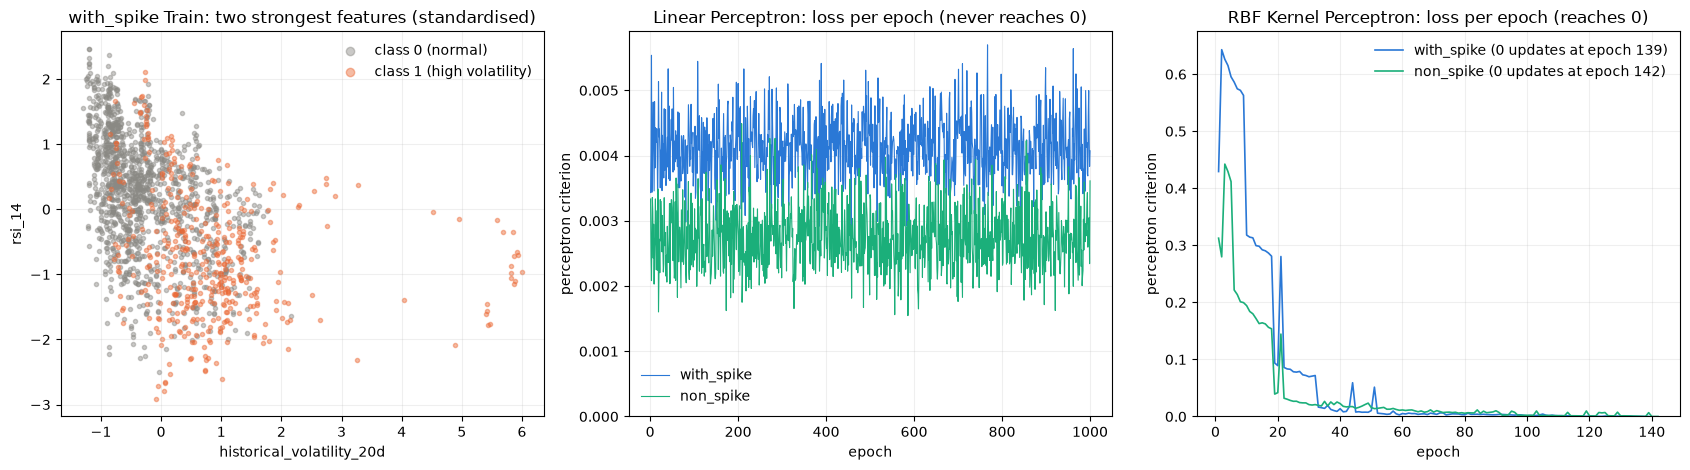

In [17]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from IPython.display import display
from src.ml.core.data import load

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
rows, histories = [], {}
for variant in ("with_spike", "non_spike"):
    train = load(variant).train
    X = (train.X - train.X.mean(axis=0)) / train.X.std(axis=0)  # the trainer's Train-only standardisation
    signed = 2 * train.y_classification - 1
    design = np.column_stack((X, np.ones(len(X))))
    # Any (w, b) meeting y_i (w.x_i + b) >= 1 on every row would be a separating hyperplane.
    lp = linprog(np.zeros(design.shape[1]), A_ub=-signed[:, None] * design, b_ub=-np.ones(len(X)),
                 bounds=[(None, None)] * design.shape[1], method="highs")
    linear = json.loads((root / "outputs" / "modeling" / variant / "classification" / "perceptron" / "history.json").read_text(encoding="utf-8"))
    kernel = json.loads((root / "outputs" / "experiments" / "kernel_perceptron" / variant / "classification" / "kernel_perceptron" / "history.json").read_text(encoding="utf-8"))
    histories[variant] = (X, train.y_classification, linear, kernel)
    rows.append({"variant": variant, "Train rows": len(X), "class 1": int(train.y_classification.sum()),
                 "separating line exists?": {0: "yes (feasible)", 2: "no (infeasible)"}.get(lp.status, lp.message),
                 "linear: epochs run": len(linear["loss"]), "linear: final loss": linear["loss"][-1],
                 "linear: lowest loss": min(linear["loss"]),
                 "kernel: epochs run": len(kernel["loss"]), "kernel: updates in last epoch": kernel["updates"][-1]})
display(pd.DataFrame(rows).round(4))

X, y, _, _ = histories["with_spike"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for label, color, name in ((0, "#8a8984", "class 0 (normal)"), (1, "#eb6834", "class 1 (high volatility)")):
    part = X[y == label]
    axes[0].scatter(part[:, 3], part[:, 6], s=9, alpha=0.45, color=color, label=name)
axes[0].set(title="with_spike Train: two strongest features (standardised)",
            xlabel="historical_volatility_20d", ylabel="rsi_14")
axes[0].legend(frameon=False, markerscale=2)
for variant, color in (("with_spike", "#2a78d6"), ("non_spike", "#1baf7a")):
    _, _, linear, kernel = histories[variant]
    axes[1].plot(linear["iteration"], linear["loss"], color=color, linewidth=0.8, label=variant)
    axes[2].plot(kernel["iteration"], kernel["loss"], color=color, linewidth=1.2,
                 label=f"{variant} (0 updates at epoch {kernel['iteration'][-1]})")
axes[1].set(title="Linear Perceptron: loss per epoch (never reaches 0)", xlabel="epoch", ylabel="perceptron criterion")
axes[2].set(title="RBF Kernel Perceptron: loss per epoch (reaches 0)", xlabel="epoch", ylabel="perceptron criterion")
axes[1].set_ylim(bottom=0)
axes[2].set_ylim(bottom=0)
for ax in axes:
    ax.grid(alpha=0.2)
axes[1].legend(frameon=False)
axes[2].legend(frameon=False)
fig.tight_layout()
plt.show()


**อ่านผล:**

- **ไม่มีเส้นแบ่ง:** linear programming ตอบ `infeasible` ทั้งสอง variant จึงไม่มีเส้นตรงใดแบ่งคลาส 0 และ 1 ใน Train ได้ถูกทุกแถว ภาพซ้ายแสดงตัวอย่างใน 2 มิติ จุดสีส้มอยู่ปนกับจุดสีเทาเป็นบริเวณกว้าง วันผันผวนสูงหลายวันมีฟีเจอร์เหมือนวันปกติ
- **กราฟของ Perceptron เส้นตรงจึงต่างจากโมเดลอื่น:** loss ไม่ลดลงแล้วราบเหมือนโมเดลที่ลด loss แบบต่อเนื่อง แต่แกว่งตลอด 1,000 epochs เพราะทุกครั้งที่แก้แถวที่ผิด จะทำให้แถวอื่นผิดแทน การเทรนจบเพราะครบโควตา ไม่ใช่เพราะลู่เข้า น้ำหนักที่ได้คือน้ำหนักหลังการแก้ครั้งสุดท้าย ไม่ใช่น้ำหนักที่ดีที่สุด ROC จึงอยู่ต่ำกว่าเส้นทแยง (ROC-AUC 0.30 และ 0.34 บน Validation) และแทบไม่ทาย positive เลย
- **Kernel แก้ได้:** RBF kernel วัดความคล้ายระหว่างวันแบบไม่เป็นเส้นตรง เท่ากับการแบ่งข้อมูลในปริภูมิที่มีมิติสูงกว่า ซึ่งสองคลาสแบ่งได้ loss ลดถึง 0 ที่ epoch 139 และ 142 ส่วนผลกับข้อมูลใหม่อยู่ในหัวข้อ 16.1 ถึง 16.4

### 16.1 อันดับบน Validation รวมโมเดล Kernel

ตารางนี้รวม Kernel Perceptron กับ leaderboard เดิมเพื่อดูอันดับ AP เท่านั้น คอลัมน์ `study` แยกผลที่ล็อกไว้กับผลทดลองหลังส่งงาน ช่วงความเชื่อมั่นและผล walk-forward ของ Kernel อยู่ในหัวข้อ 16.3–16.4 จึงไม่ใช้ตารางนี้เปลี่ยน headline เดิม


In [18]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
experiment = root / "outputs" / "experiments" / "kernel_perceptron"
summary = {row["variant"]: row for row in json.loads((experiment / "summary.json").read_text(encoding="utf-8"))}
for variant in ("with_spike", "non_spike"):
    original = pd.read_csv(root / "outputs" / "modeling" / "report" / variant / "leaderboard_classification.csv")
    original = original[["model", "kind", "average_precision", "roc_auc", "f1", "recall", "precision", "specificity", "accuracy"]].copy()
    original["study"] = "locked study"
    selected = next(row for row in summary[variant]["candidates"] if row["id"] == summary[variant]["selected"])
    run = experiment / variant / "classification" / "kernel_perceptron"
    metrics = json.loads((run / "validation_metrics.json").read_text(encoding="utf-8"))
    kernel = {"model": "kernel_perceptron", "kind": "model", "study": "post-submission"}
    for field in ("average_precision", "roc_auc", "f1", "recall", "precision", "specificity", "accuracy"):
        kernel[field] = metrics[field]["value"]
    board = pd.concat([original, pd.DataFrame([kernel])], ignore_index=True)
    board = board.sort_values("average_precision", ascending=False).reset_index(drop=True)
    board.insert(0, "AP rank", board["average_precision"].rank(method="min", ascending=False).astype(int))
    print(f"{variant}: Validation ranking including supplementary kernel (gamma={selected['gamma']})")
    display(board.round(4))
    print("Kernel confusion matrix [[TN, FP], [FN, TP]]:", metrics["confusion_matrix"])


with_spike: Validation ranking including supplementary kernel (gamma=1.0)


,AP rank,model,kind,average_precision,roc_auc,f1,recall,precision,specificity,accuracy,study
0,1,mlp,model,0.2668,0.6757,0.3200,0.2353,0.5000,0.9763,0.9084,locked study
1,2,random_forest,model,0.2548,0.6862,0.2917,0.2059,0.5000,0.9792,0.9084,locked study
2,3,gradient_boosting,model,0.2531,0.6754,0.2449,0.1765,0.4000,0.9733,0.9003,locked study
3,4,svm,model,0.2514,0.6786,0.2553,0.1765,0.4615,0.9792,0.9057,locked study
4,5,xgboost,model,0.2508,0.6693,0.2449,0.1765,0.4000,0.9733,0.9003,locked study
5,6,baseline_persistence,baseline,0.2474,0.7214,0.2899,0.2941,0.2857,0.9258,0.8679,locked study
6,7,slp,model,0.2427,0.6803,0.2609,0.1765,0.5000,0.9822,0.9084,locked study
7,8,adaboost,model,0.2363,0.6768,0.2222,0.1765,0.3000,0.9585,0.8868,locked study
8,9,logistic,model,0.2330,0.6732,0.2609,0.1765,0.5000,0.9822,0.9084,locked study
9,10,stacking,model,0.2262,0.6641,0.2353,0.1765,0.3529,0.9674,0.8949,locked study


Kernel confusion matrix [[TN, FP], [FN, TP]]: [[291, 46], [23, 11]]
non_spike: Validation ranking including supplementary kernel (gamma=0.75)


,AP rank,model,kind,average_precision,roc_auc,f1,recall,precision,specificity,accuracy,study
0,1,random_forest,model,0.3010,0.6766,0.2917,0.2059,0.5000,0.9792,0.9084,locked study
1,2,mlp,model,0.2808,0.6992,0.3077,0.2353,0.4444,0.9703,0.9030,locked study
2,3,xgboost,model,0.2652,0.6853,0.2800,0.2059,0.4375,0.9733,0.9030,locked study
3,4,gradient_boosting,model,0.2525,0.6732,0.2667,0.1765,0.5455,0.9852,0.9111,locked study
4,5,logistic,model,0.2513,0.6824,0.2553,0.1765,0.4615,0.9792,0.9057,locked study
5,6,svm,model,0.2501,0.6804,0.2727,0.1765,0.6000,0.9881,0.9137,locked study
6,7,baseline_persistence,baseline,0.2474,0.7214,0.2899,0.2941,0.2857,0.9258,0.8679,locked study
7,8,slp,model,0.2474,0.6778,0.2258,0.2059,0.2500,0.9377,0.8706,locked study
8,9,adaboost,model,0.2407,0.6409,0.2353,0.1765,0.3529,0.9674,0.8949,locked study
9,10,stacking,model,0.2311,0.6650,0.1961,0.1471,0.2941,0.9644,0.8895,locked study


Kernel confusion matrix [[TN, FP], [FN, TP]]: [[316, 21], [32, 2]]


### 16.2 กราฟการฝึกและผลบน Validation

จำนวนการอัปเดตต่อ epoch แสดงการลู่เข้าบน Train; กราฟ ROC/PR เทียบกับ Perceptron แบบเส้นตรงบน Validation ชุดเดียวกัน และ confusion matrix แสดงผลของ Kernel ที่เกณฑ์ score 0 การลู่เข้าบน Train ไม่ยืนยันประสิทธิภาพกับข้อมูลใหม่


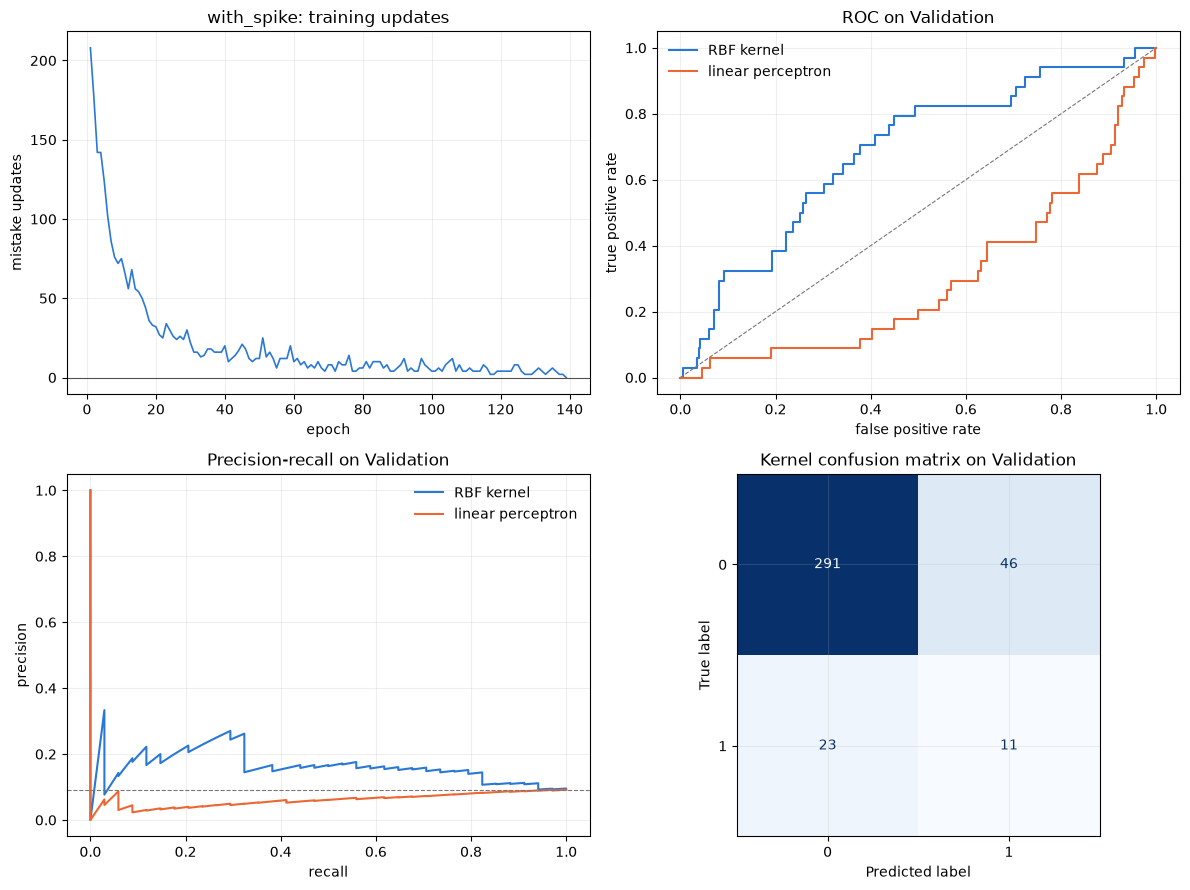

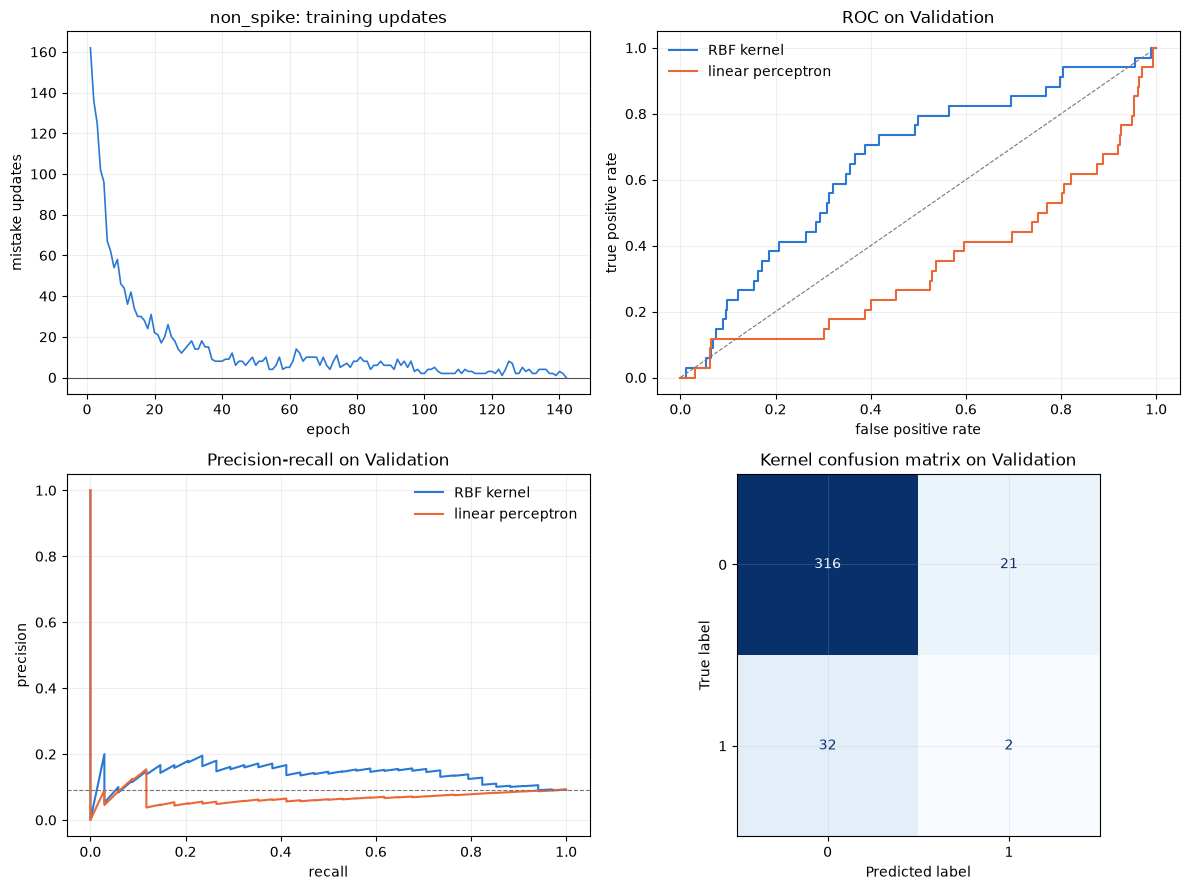

In [19]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve, roc_curve

for variant in ("with_spike", "non_spike"):
    run = experiment / variant / "classification" / "kernel_perceptron"
    history = json.loads((run / "history.json").read_text(encoding="utf-8"))
    kernel = pd.read_csv(run / "validation_predictions.csv")
    linear = pd.read_csv(root / "outputs" / "modeling" / variant / "classification" / "perceptron" / "validation_predictions.csv")
    assert kernel["Date"].equals(linear["Date"]) and np.array_equal(kernel["target"], linear["target"])
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    axes[0, 0].plot(history["iteration"], history["updates"], color="#2a78d6", linewidth=1.2)
    axes[0, 0].axhline(0, color="#52514e", linewidth=0.8)
    axes[0, 0].set(title=f"{variant}: training updates", xlabel="epoch", ylabel="mistake updates")
    for frame, label, color in ((kernel, "RBF kernel", "#2a78d6"), (linear, "linear perceptron", "#eb6834")):
        fpr, tpr, _ = roc_curve(frame["target"], frame["raw_score"])
        precision, recall, _ = precision_recall_curve(frame["target"], frame["raw_score"])
        axes[0, 1].plot(fpr, tpr, label=label, color=color)
        axes[1, 0].plot(recall, precision, label=label, color=color)
    axes[0, 1].plot([0, 1], [0, 1], linestyle="--", color="#777777", linewidth=0.8)
    axes[1, 0].axhline(kernel["target"].mean(), linestyle="--", color="#777777", linewidth=0.8)
    axes[0, 1].set(title="ROC on Validation", xlabel="false positive rate", ylabel="true positive rate")
    axes[1, 0].set(title="Precision-recall on Validation", xlabel="recall", ylabel="precision")
    ConfusionMatrixDisplay.from_predictions(kernel["target"], kernel["final_prediction"], labels=[0, 1],
                                            colorbar=False, ax=axes[1, 1], cmap="Blues")
    axes[1, 1].set_title("Kernel confusion matrix on Validation")
    for ax in (axes[0, 1], axes[1, 0]):
        ax.legend(frameon=False)
    for ax in axes.flat:
        ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()


### 16.3 ความทนทานตามเวลาและฟีเจอร์สำคัญ

ฝึกใหม่ใน expanding-window 4 fold ภายใน Train โดยใช้ `gamma` ที่เลือกไว้แล้วและเว้นระยะ 5 วันก่อนแต่ละ block; คะแนน pooled มาจากการรวมคำทำนายของ fold ที่แยกตามเวลา ส่วน feature importance คือค่า AP ที่ลดลงหลังสลับฟีเจอร์เป็นก้อน 20 วันบน Validation ทำซ้ำ 30 ครั้ง ค่าใกล้ศูนย์หรือติดลบไม่ใช่หลักฐานว่าฟีเจอร์มีประโยชน์


with_spike: supplementary Validation leaderboard with 95% moving-block intervals


,ap_rank,model,study,average_precision,average_precision_low,average_precision_high,roc_auc,roc_auc_low,roc_auc_high,recall,f1
0,1,mlp,locked study,0.2668,0.0579,0.4724,0.6757,0.3961,0.8474,0.2353,0.3200
1,2,random_forest,locked study,0.2548,0.0603,0.4586,0.6862,0.4634,0.8323,0.2059,0.2917
2,3,gradient_boosting,locked study,0.2531,0.0548,0.4746,0.6754,0.4075,0.8409,0.1765,0.2449
3,4,svm,locked study,0.2514,0.0514,0.4651,0.6786,0.4339,0.8404,0.1765,0.2553
4,5,xgboost,locked study,0.2508,0.0559,0.4681,0.6693,0.4080,0.8368,0.1765,0.2449
5,6,baseline_persistence,locked study,0.2474,0.0545,0.5002,0.7214,0.5384,0.8407,0.2941,0.2899
6,7,slp,locked study,0.2427,0.0545,0.4432,0.6803,0.4458,0.8289,0.1765,0.2609
7,8,adaboost,locked study,0.2363,0.0626,0.4381,0.6768,0.4602,0.8196,0.1765,0.2222
8,9,logistic,locked study,0.2330,0.0526,0.4301,0.6732,0.4224,0.8305,0.1765,0.2609
9,10,stacking,locked study,0.2262,0.0551,0.4176,0.6641,0.4218,0.8155,0.1765,0.2353


non_spike: supplementary Validation leaderboard with 95% moving-block intervals


,ap_rank,model,study,average_precision,average_precision_low,average_precision_high,roc_auc,roc_auc_low,roc_auc_high,recall,f1
0,1,random_forest,locked study,0.3010,0.0548,0.5328,0.6766,0.4439,0.8313,0.2059,0.2917
1,2,mlp,locked study,0.2808,0.0534,0.5184,0.6992,0.4716,0.8426,0.2353,0.3077
2,3,xgboost,locked study,0.2652,0.0600,0.4730,0.6853,0.4608,0.8256,0.2059,0.2800
3,4,gradient_boosting,locked study,0.2525,0.0625,0.4477,0.6732,0.4577,0.8152,0.1765,0.2667
4,5,logistic,locked study,0.2513,0.0538,0.4557,0.6824,0.4529,0.8310,0.1765,0.2553
5,6,svm,locked study,0.2501,0.0520,0.4672,0.6804,0.4367,0.8413,0.1765,0.2727
6,7,baseline_persistence,locked study,0.2474,0.0545,0.5002,0.7214,0.5384,0.8407,0.2941,0.2899
7,8,slp,locked study,0.2474,0.0489,0.4531,0.6778,0.4892,0.8122,0.2059,0.2258
8,9,adaboost,locked study,0.2407,0.0556,0.4722,0.6409,0.3618,0.8209,0.1765,0.2353
9,10,stacking,locked study,0.2311,0.0582,0.4204,0.6650,0.4550,0.8061,0.1471,0.1961


,variant,fold,train_rows,block_rows,positives,epochs,converged,average_precision,roc_auc,f1,recall,average_precision_low,average_precision_high
0,with_spike,0,688.0,260,80,53.0,True,0.4948,0.7715,0.0000,0.0000,NaN,NaN
1,with_spike,1,948.0,260,77,31.0,True,0.5442,0.7318,0.4677,0.3766,NaN,NaN
2,with_spike,2,1208.0,260,119,98.0,True,0.7021,0.7714,0.6275,0.5378,NaN,NaN
3,with_spike,3,1468.0,260,77,145.0,True,0.4071,0.6466,0.4250,0.4416,NaN,NaN
4,with_spike,pooled,NaN,1040,353,NaN,NaN,0.5127,0.7144,0.4456,0.3598,0.4049,0.6249
5,non_spike,0,663.0,183,20,51.0,True,0.2029,0.7052,0.0870,0.0500,NaN,NaN
6,non_spike,1,848.0,233,55,62.0,True,0.4189,0.7075,0.0351,0.0182,NaN,NaN
7,non_spike,2,1079.0,226,86,82.0,True,0.5727,0.7150,0.0667,0.0349,NaN,NaN
8,non_spike,3,1305.0,210,50,148.0,True,0.3473,0.6527,0.1250,0.0800,NaN,NaN
9,non_spike,pooled,NaN,852,211,NaN,NaN,0.3987,0.7133,0.0769,0.0427,0.2899,0.5231


,variant,model,task,feature,metric,baseline,importance_mean,importance_std
11,non_spike,kernel_perceptron,classification,historical_volatility_20d,average_precision,0.1460,0.0168,0.0118
13,non_spike,kernel_perceptron,classification,sma_ratio_5_20,average_precision,0.1460,0.0114,0.0198
14,non_spike,kernel_perceptron,classification,rsi_14,average_precision,0.1460,0.0093,0.0170
10,non_spike,kernel_perceptron,classification,historical_volatility_5d,average_precision,0.1460,0.0066,0.0171
12,non_spike,kernel_perceptron,classification,intraday_range,average_precision,0.1460,0.0054,0.0157
15,non_spike,kernel_perceptron,classification,volume_zscore_20,average_precision,0.1460,-0.0035,0.0207
8,non_spike,kernel_perceptron,classification,return_1d,average_precision,0.1460,-0.0074,0.0145
9,non_spike,kernel_perceptron,classification,return_5d,average_precision,0.1460,-0.0171,0.0323
6,with_spike,kernel_perceptron,classification,rsi_14,average_precision,0.1732,0.0317,0.0195
3,with_spike,kernel_perceptron,classification,historical_volatility_20d,average_precision,0.1732,0.0282,0.0106


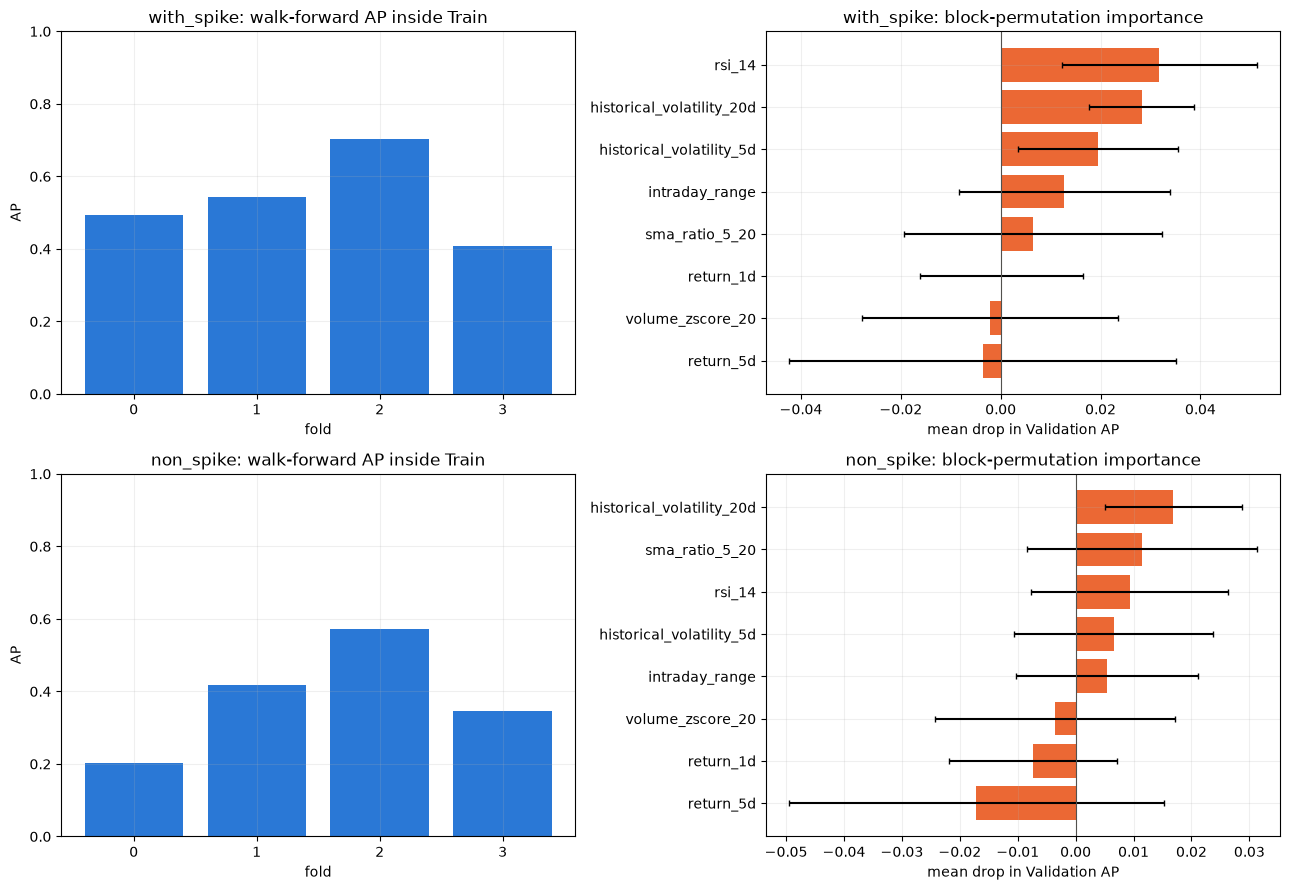

In [20]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
report = root / "outputs" / "experiments" / "kernel_perceptron" / "report"
walk = pd.read_csv(report / "walk_forward.csv")
importance = pd.read_csv(report / "feature_importance.csv")
for variant in ("with_spike", "non_spike"):
    board = pd.read_csv(report / f"leaderboard_validation_{variant}.csv")
    fields = ["ap_rank", "model", "study", "average_precision", "average_precision_low", "average_precision_high",
              "roc_auc", "roc_auc_low", "roc_auc_high", "recall", "f1"]
    print(f"{variant}: supplementary Validation leaderboard with 95% moving-block intervals")
    display(board[fields].round(4))
display(walk[["variant", "fold", "train_rows", "block_rows", "positives", "epochs", "converged",
              "average_precision", "roc_auc", "f1", "recall", "average_precision_low", "average_precision_high"]].round(4))
display(importance.sort_values(["variant", "importance_mean"], ascending=[True, False]).round(4))
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for row, variant in enumerate(("with_spike", "non_spike")):
    folds = walk[(walk["variant"] == variant) & (walk["fold"] != "pooled")]
    axes[row, 0].bar(folds["fold"].astype(str), folds["average_precision"], color="#2a78d6")
    axes[row, 0].set(title=f"{variant}: walk-forward AP inside Train", xlabel="fold", ylabel="AP", ylim=(0, 1))
    part = importance[importance["variant"] == variant].sort_values("importance_mean")
    axes[row, 1].barh(part["feature"], part["importance_mean"], xerr=part["importance_std"],
                      color="#eb6834", error_kw={"capsize": 2})
    axes[row, 1].axvline(0, color="#52514e", linewidth=0.8)
    axes[row, 1].set(title=f"{variant}: block-permutation importance", xlabel="mean drop in Validation AP")
for ax in axes.flat:
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


### 16.4 ช่วงความเชื่อมั่นและการตรวจเทียบ RBF kernel

ช่วง 95% ใช้ moving-block bootstrap ก้อน 20 วัน 2,000 รอบและสุ่มแถวคู่กันทุกโมเดล ค่า `kernel minus reference` เป็นผลต่างแบบ paired; ช่วงที่คร่อมศูนย์ยังสรุปความต่างไม่ได้ การตรวจเทียบใช้ `sklearn.metrics.pairwise.rbf_kernel` ทั้งกับโมเดลที่บันทึกไว้และการฝึกแบบคำนวณคะแนนใหม่ทุกครั้ง `with_spike` หยุดคนละ epoch เพราะคะแนนบางแถวใกล้ศูนย์มาก จึงไม่อ้างว่าขั้นตอนฝึกตรงกันทุกอัปเดต


In [21]:
import json
import pandas as pd
from IPython.display import display

rows = []
for variant in ("with_spike", "non_spike"):
    result = json.loads((report / f"bootstrap_validation_{variant}.json").read_text(encoding="utf-8"))
    for reference, fields in result["paired_delta_vs_kernel"].items():
        for metric in ("average_precision", "roc_auc", "f1", "recall"):
            value = fields[metric]
            rows.append({"variant": variant, "reference": reference, "metric": metric,
                         "kernel minus reference": value["point"], "95% low": value["low"],
                         "95% high": value["high"], "excludes zero": value["excludes_zero"]})
display(pd.DataFrame(rows).round(4))
display(pd.DataFrame(json.loads((report / "reference_parity.json").read_text(encoding="utf-8"))))
display(pd.DataFrame(json.loads((report / "training_reference.json").read_text(encoding="utf-8"))).round(4))


,variant,reference,metric,kernel minus reference,95% low,95% high,excludes zero
0,with_spike,linear_perceptron,average_precision,0.1084,0.0100,0.2372,True
1,with_spike,linear_perceptron,roc_auc,0.3842,0.0593,0.5959,True
2,with_spike,linear_perceptron,f1,0.2418,0.0392,0.3750,True
3,with_spike,linear_perceptron,recall,0.3235,0.0667,0.5250,True
4,with_spike,locked_headline,average_precision,-0.0936,-0.2209,0.0792,False
5,with_spike,locked_headline,roc_auc,0.0078,-0.1471,0.2072,False
6,with_spike,locked_headline,f1,-0.0782,-0.2494,0.2250,False
7,with_spike,locked_headline,recall,0.0882,-0.0656,0.3750,False
8,non_spike,linear_perceptron,average_precision,0.0718,-0.0417,0.1855,False
9,non_spike,linear_perceptron,roc_auc,0.3151,-0.0559,0.5753,False


,max_abs_score_difference,passed,prediction_agreement,reference,samples,scope,support_vectors,variant
0,4.463097e-14,True,1.0,sklearn.metrics.pairwise.rbf_kernel,371,saved model inference; sklearn has no equivalent online Kernel Perceptron class,929,with_spike
1,5.728751e-14,True,1.0,sklearn.metrics.pairwise.rbf_kernel,371,saved model inference; sklearn has no equivalent online Kernel Perceptron class,722,non_spike


,converged,epochs,first_update_count_mismatch_epoch,interpretation,reference,same_update_history,saved_epochs,saved_validation_average_precision,train_accuracy,validation_average_precision,validation_label_agreement,variant
0,True,144,15.0,floating-point order can change updates near zero; both runs still converge,sklearn RBF matrix + recomputed dual decision at each step,False,139,0.1732,1.0,0.1744,0.9677,with_spike
1,True,142,NaN,floating-point order can change updates near zero; both runs still converge,sklearn RBF matrix + recomputed dual decision at each step,True,142,0.1460,1.0,0.1460,1.0000,non_spike


## 17. ผลทดลองเพิ่มเติมหลังนำเสนอ: Transfer learning ด้วย Transformer/GRU

อาจารย์เสนอหลังการนำเสนอว่า ให้ลองโมเดลลำดับเวลาที่ **เรียนจากหุ้นและดัชนีตัวอื่นก่อน** แล้วค่อยปรับเข้ากับ QQQ หัวข้อนี้แสดงผลบน Validation ของการทดลองนั้น ซึ่งแยกจาก 13 classifiers เดิมและไม่เปลี่ยน leaderboard ที่ล็อกไว้ ทุกตัวเลขอ่านจาก [`outputs/experiments/transfer_learning/`](../outputs/experiments/transfer_learning/) ไม่มีการฝึกและไม่เปิด Test ใน notebook นี้

- **ข้อมูลตลาดอื่น:** ETF 10 ตัว (SPY, DIA, IWM, XLK, XLF, XLE, XLV, XLY, EFA, EEM) จาก Nasdaq endpoint เดียวกับ QQQ ใช้ 8 ฟีเจอร์สูตรเดิม และตัดที่ 2023-08-18 ซึ่งเป็นวันสุดท้ายของ QQQ Train
- **โมเดล:** Transformer (2 ชั้น, d=32, 4 heads) และ GRU (hidden 32) อ่านย้อนหลัง 60 วัน เขียนด้วย NumPy ทั้งหมด **รวมถึง autograd** และตรวจ gradient ทุก op ด้วย finite difference
- **สามขั้นของการเรียน:** (1) self-supervised (SSL) เติมช่วง 5 วันที่ถูกซ่อนบน ETF (2) domain-adaptive pretraining (DAPT) ทำแบบเดียวกันบนฟีเจอร์ของ QQQ Train โดยไม่ใช้ label (3) fine-tune ด้วย label ของ QQQ
- **Arms:** `scratch` = ไม่ pretrain, `ssl` = ขั้น 1 แล้ว fine-tune, `full` = ขั้น 1+2 แล้ว fine-tune (โมเดลหลัก `T-full` ล็อกไว้ก่อนดูผล), `probe` = ขั้น 1+2 แล้วฝึกแค่ head ส่วน `T-` คือ Transformer และ `G-` คือ GRU
- คะแนนของแต่ละ arm เป็นค่าเฉลี่ยความน่าจะเป็นของ 3 seeds ใช้ config ที่ตั้งไว้ล่วงหน้าโดยไม่ค้น hyperparameter และรันทั้งสอง variant เหมือนโมเดลอื่น

รายละเอียดเต็มอยู่ที่ [บันทึกการทดลอง](../docs/models/transfer_learning/EXPERIMENT.md) ส่วนผล Test และ holdout อยู่ใน notebook 05 หัวข้อ 12

### 17.1 อันดับบน Validation รวม arm ใหม่

ตารางนี้ใส่ arm ใหม่ทั้ง 8 ตัวลงใน leaderboard เดิมเพื่อดูอันดับ AP เท่านั้น คอลัมน์ `study` แยกผลที่ล็อกไว้ (`locked study`) ออกจากผลหลังนำเสนอ (`post-presentation`) การหยิบ arm ที่ได้อันดับดีที่สุดมาอ้างหลังเห็นผลคือ selection bias ตัวที่ล็อกไว้ล่วงหน้าคือ `T-full`

In [22]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
tl = root / "outputs" / "experiments" / "transfer_learning"
ARMS = ["T-scratch", "T-ssl", "T-full", "T-probe", "G-scratch", "G-ssl", "G-full", "G-probe"]
HUE = {"T": "#2a78d6", "G": "#eb6834", "mlp": "#1baf7a", "baseline_persistence": "#8a8984"}

for variant in ("with_spike", "non_spike"):
    original = pd.read_csv(root / "outputs" / "modeling" / "report" / variant / "leaderboard_classification.csv")
    fields = ["model", "kind", "average_precision", "roc_auc", "f1", "recall", "precision"]
    original = original[fields].copy()
    original["study"] = "locked study"
    summary = {row["model"]: row for row in json.loads((tl / variant / "validation_summary.json").read_text(encoding="utf-8"))["leaderboard"]}
    new = pd.DataFrame([{"model": arm, "kind": "model", "study": "post-presentation",
                         **{f: summary[arm][f] for f in fields[2:]}} for arm in ARMS])
    board = pd.concat([original, new], ignore_index=True).sort_values("average_precision", ascending=False).reset_index(drop=True)
    board.insert(0, "AP rank", board["average_precision"].rank(method="min", ascending=False).astype(int))
    print(f"{variant}: Validation ranking with the eight transfer-learning arms ({len(original)} locked rows + 8)")
    display(board.round(4))


with_spike: Validation ranking with the eight transfer-learning arms (15 locked rows + 8)


,AP rank,model,kind,average_precision,roc_auc,f1,recall,precision,study
0,1,G-probe,model,0.2911,0.7068,0.2985,0.5882,0.2000,post-presentation
1,2,mlp,model,0.2668,0.6757,0.3200,0.2353,0.5000,locked study
2,3,G-ssl,model,0.2665,0.7095,0.3077,0.5294,0.2169,post-presentation
3,4,G-full,model,0.2652,0.7095,0.3125,0.5882,0.2128,post-presentation
4,5,G-scratch,model,0.2582,0.7140,0.3226,0.4412,0.2542,post-presentation
5,6,random_forest,model,0.2548,0.6862,0.2917,0.2059,0.5000,locked study
6,7,gradient_boosting,model,0.2531,0.6754,0.2449,0.1765,0.4000,locked study
7,8,svm,model,0.2514,0.6786,0.2553,0.1765,0.4615,locked study
8,9,xgboost,model,0.2508,0.6693,0.2449,0.1765,0.4000,locked study
9,10,baseline_persistence,baseline,0.2474,0.7214,0.2899,0.2941,0.2857,locked study


non_spike: Validation ranking with the eight transfer-learning arms (15 locked rows + 8)


,AP rank,model,kind,average_precision,roc_auc,f1,recall,precision,study
0,1,random_forest,model,0.3010,0.6766,0.2917,0.2059,0.5000,locked study
1,2,mlp,model,0.2808,0.6992,0.3077,0.2353,0.4444,locked study
2,3,G-scratch,model,0.2755,0.7132,0.3101,0.5882,0.2105,post-presentation
3,4,G-full,model,0.2725,0.7088,0.2958,0.6176,0.1944,post-presentation
4,5,G-ssl,model,0.2673,0.7032,0.2767,0.6471,0.1760,post-presentation
5,6,xgboost,model,0.2652,0.6853,0.2800,0.2059,0.4375,locked study
6,7,G-probe,model,0.2595,0.7119,0.2685,0.5882,0.1739,post-presentation
7,8,gradient_boosting,model,0.2525,0.6732,0.2667,0.1765,0.5455,locked study
8,9,logistic,model,0.2513,0.6824,0.2553,0.1765,0.4615,locked study
9,10,svm,model,0.2501,0.6804,0.2727,0.1765,0.6000,locked study


**อ่านตาราง:** GRU ทุก arm อยู่กลุ่มบนใกล้ MLP และ persistence ส่วน Transformer ทุก arm อยู่ท้ายตาราง (AP ใกล้สัดส่วน positive 0.092) อันดับที่ต่างกันเล็กน้อยในกลุ่มบนแยกกันไม่ได้ทางสถิติ ดูช่วงความเชื่อมั่นในหัวข้อ 17.3

### 17.2 กราฟ pretraining, fine-tune และ PR บน Validation

แต่ละ variant มีสี่กราฟ:

1. **masked MSE ระหว่าง SSL → DAPT:** วัดบน 512 window ของ QQQ Train ที่ตรึงไว้ โดย SSL ฝึกครั้งเดียวต่อ seed และใช้ร่วมกันทั้งสอง variant
2. **AP บน 15% ท้ายของ Train ต่อ epoch ตอน fine-tune:** ใช้หยุดก่อนกำหนด
3. **precision-recall บน Validation**
4. **confusion matrix ของ `T-full`**

masked loss ที่ลดลงแปลว่าโมเดลเติมข้อมูลที่หายไปได้ดีขึ้น แต่ไม่ได้แปลว่าทำนายความผันผวนในอนาคตได้ดีขึ้น

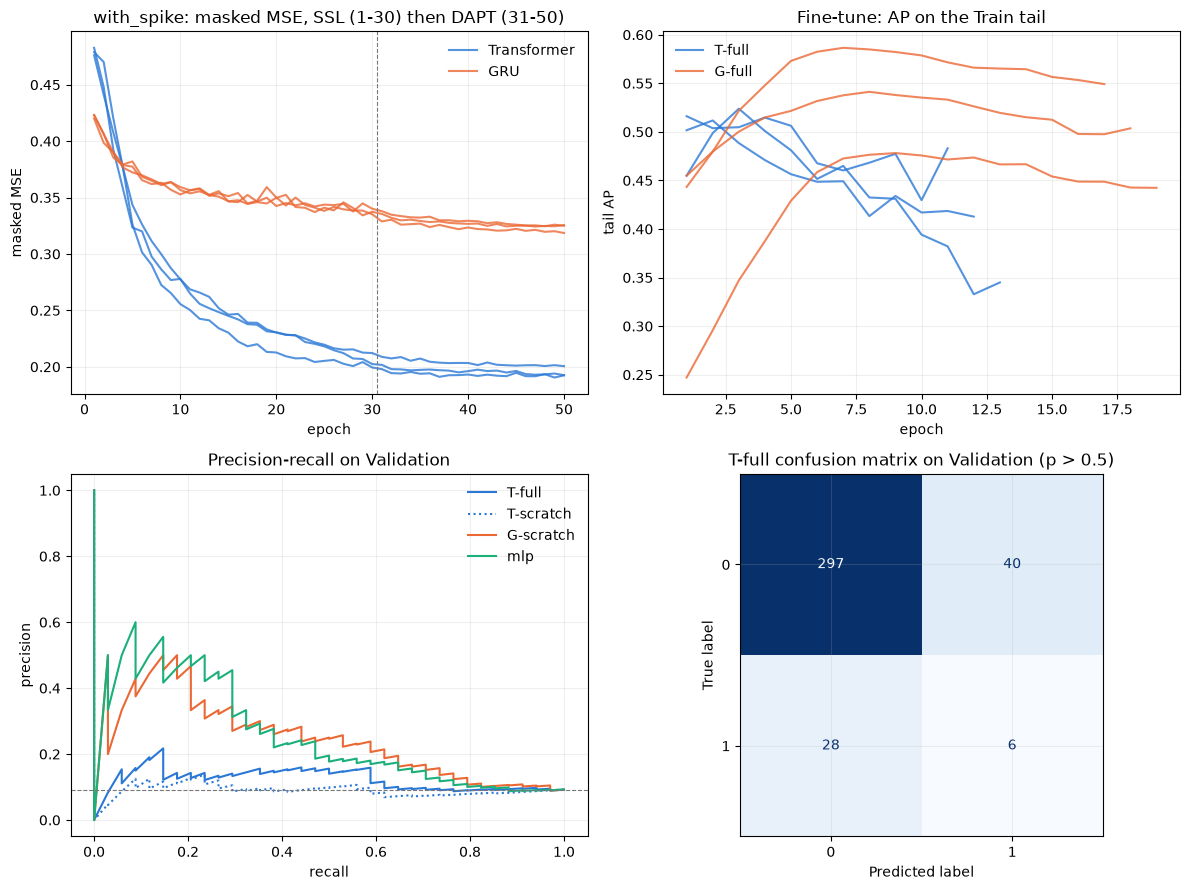

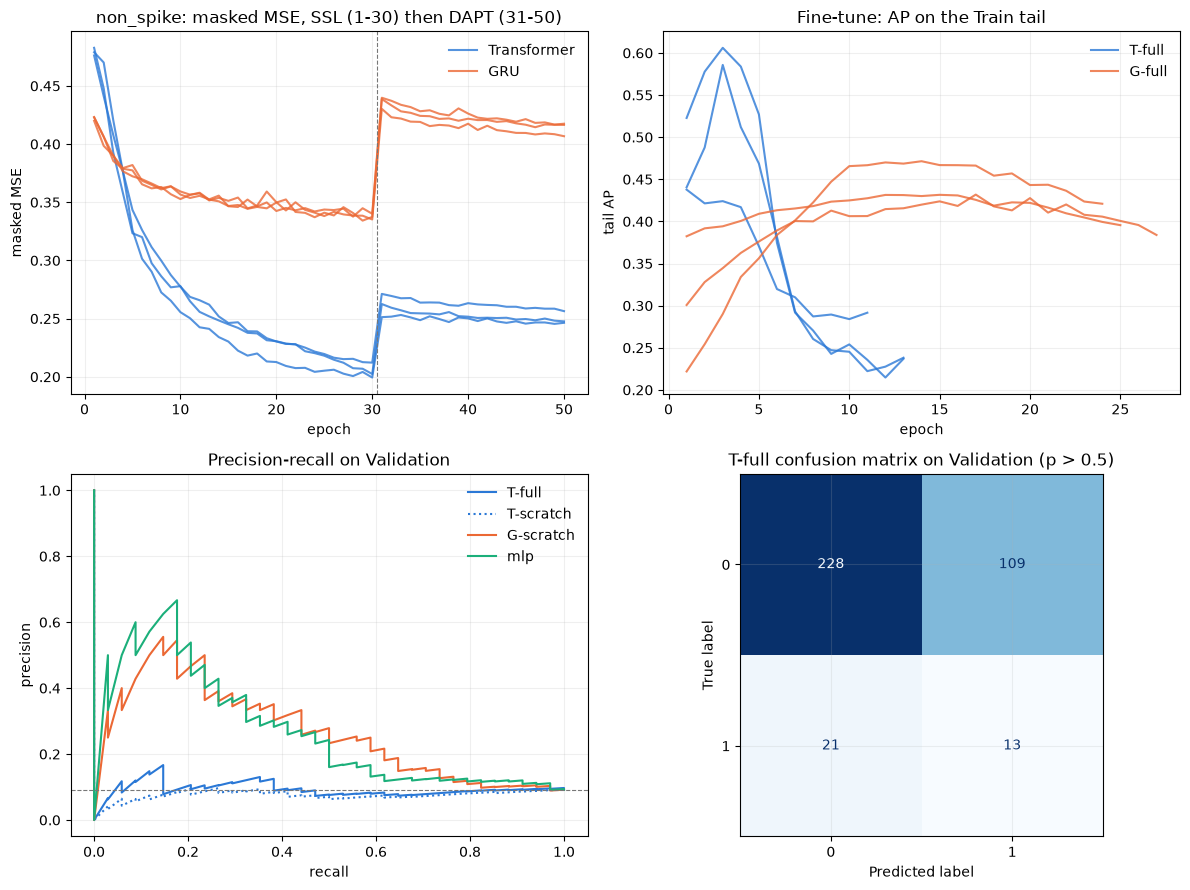

In [23]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
tl = root / "outputs" / "experiments" / "transfer_learning"
ARMS = ["T-scratch", "T-ssl", "T-full", "T-probe", "G-scratch", "G-ssl", "G-full", "G-probe"]
HUE = {"T": "#2a78d6", "G": "#eb6834", "mlp": "#1baf7a", "baseline_persistence": "#8a8984"}
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve

runs = tl / "runs"
for variant in ("with_spike", "non_spike"):
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    for prefix in ("T", "G"):
        for k, seed_dir in enumerate(sorted((runs / f"{prefix}-pretrain").glob("seed_*"))):
            ssl = json.loads((seed_dir / "history.json").read_text(encoding="utf-8"))["ssl"]["monitor_loss"]
            dapt = json.loads((runs / variant / f"{prefix}-dapt" / seed_dir.name / "history.json").read_text(encoding="utf-8"))["dapt"]["monitor_loss"]
            label = ("Transformer" if prefix == "T" else "GRU") if k == 0 else None
            axes[0, 0].plot(range(1, len(ssl) + len(dapt) + 1), ssl + dapt, color=HUE[prefix], alpha=0.8, label=label)
            tail = json.loads((runs / variant / f"{prefix}-full" / seed_dir.name / "history.json").read_text(encoding="utf-8"))["tail_ap"]
            axes[0, 1].plot(range(1, len(tail) + 1), tail, color=HUE[prefix], alpha=0.8, label=f"{prefix}-full" if k == 0 else None)
    axes[0, 0].axvline(30.5, color="#777777", linestyle="--", linewidth=0.8)
    axes[0, 0].set(title=f"{variant}: masked MSE, SSL (1-30) then DAPT (31-50)", xlabel="epoch", ylabel="masked MSE")
    axes[0, 1].set(title="Fine-tune: AP on the Train tail", xlabel="epoch", ylabel="tail AP")
    curves = {}
    for arm in ("T-full", "T-scratch", "G-scratch"):
        frames = [pd.read_csv(runs / variant / arm / f"seed_{s}" / "validation_predictions.csv") for s in (0, 1, 2)]
        curves[arm] = (frames[0]["target"], np.mean([f["raw_score"] for f in frames], axis=0))
    mlp = pd.read_csv(root / "outputs" / "modeling" / variant / "classification" / "mlp" / "validation_predictions.csv")
    curves["mlp"] = (mlp["target"], mlp["raw_score"])
    style = {"T-full": ("#2a78d6", "-"), "T-scratch": ("#2a78d6", ":"), "G-scratch": ("#eb6834", "-"), "mlp": ("#1baf7a", "-")}
    for name, (y, score) in curves.items():
        precision, recall, _ = precision_recall_curve(y, score)
        axes[1, 0].plot(recall, precision, color=style[name][0], linestyle=style[name][1], label=name)
    axes[1, 0].axhline(curves["mlp"][0].mean(), color="#777777", linestyle="--", linewidth=0.8)
    axes[1, 0].set(title="Precision-recall on Validation", xlabel="recall", ylabel="precision")
    y, score = curves["T-full"]
    ConfusionMatrixDisplay.from_predictions(y, (score > 0.5).astype(int), labels=[0, 1], colorbar=False, ax=axes[1, 1], cmap="Blues")
    axes[1, 1].set_title("T-full confusion matrix on Validation (p > 0.5)")
    for ax in (axes[0, 0], axes[0, 1], axes[1, 0]):
        ax.legend(frameon=False)
    for ax in axes.flat:
        ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()


**อ่านกราฟ:**

- **masked MSE:** Transformer เติมฟีเจอร์ที่หายไปได้ดีกว่า GRU มาก เพราะเห็นวันทั้งก่อนและหลังช่วงที่ถูกซ่อน ส่วน GRU อ่านทางเดียว
- **ตอน fine-tune:** tail AP ของ Transformer ขึ้นสูงสุดภายใน epoch 1–3 แล้วตก ซึ่งเป็นอาการ overfit เร็ว (20 จาก 24 runs) ขณะที่ GRU ค่อย ๆ ดีขึ้นและไม่มี run ใดดีที่สุดก่อน epoch 4 (ช่วง epoch ที่ดีที่สุดคือ 4–68)
- **บน Validation:** PR curve ของ Transformer อยู่ใกล้เส้นสัดส่วน positive ตลอด ส่วน GRU ซ้อนกับ MLP
- **ใน non_spike:** loss กระโดดที่ epoch 31 เพราะชุด window ที่ใช้วัดเปลี่ยนจาก with_spike เป็น non_spike ไม่ได้แปลว่าโมเดลแย่ลง

### 17.3 ผลต่างแบบ paired และเกณฑ์ที่ตั้งไว้ก่อน

ผลต่าง AP คำนวณบนวันเดียวกัน ช่วง 95% มาจาก moving-block bootstrap ก้อน 20 วัน 2,000 รอบ ช่วงที่คร่อมศูนย์ยังสรุปว่าต่างกันไม่ได้ เกณฑ์ที่ตั้งไว้ก่อนดูผลมีสองข้อ:

- **transfer ช่วย:** `T-full` > `T-scratch` และชนะอย่างน้อย 2 ใน 3 seeds
- **เหนือ baseline ชัดเจน:** AP สูงกว่า MLP และ persistence อย่างน้อย 0.05 และช่วงไม่คร่อมศูนย์

,variant,comparison,AP difference,95% low,95% high,excludes zero
0,with_spike,T-full - T-scratch,0.0346,0.0025,0.1305,True
1,with_spike,T-full - T-ssl,0.0046,-0.0156,0.0259,False
2,with_spike,T-full - mlp,-0.1376,-0.3029,0.0743,False
3,with_spike,T-full - baseline_persistence,-0.1182,-0.3160,0.1003,False
4,with_spike,G-full - G-scratch,0.0070,-0.0841,0.0623,False
5,with_spike,G-scratch - mlp,-0.0086,-0.0480,0.0506,False
6,with_spike,G-scratch - baseline_persistence,0.0108,-0.0645,0.0881,False
7,non_spike,T-full - T-scratch,0.0192,-0.0025,0.0954,False
8,non_spike,T-full - T-ssl,0.0015,-0.0093,0.0051,False
9,non_spike,T-full - mlp,-0.1823,-0.4073,0.0814,False


,variant,transfer_helps,seed_wins_vs_scratch,clearly_beats_baselines
0,with_spike,True,3,False
1,non_spike,True,2,False


,variant,arm,seed 0,seed 1,seed 2,ensemble AP
9,non_spike,G-full,0.2676,0.2415,0.2680,0.2725
11,non_spike,G-probe,0.2892,0.2454,0.2194,0.2595
8,non_spike,G-scratch,0.2722,0.2718,0.2911,0.2755
10,non_spike,G-ssl,0.2749,0.2263,0.2698,0.2673
13,non_spike,T-full,0.1009,0.0807,0.1013,0.0985
12,non_spike,T-probe,0.1342,0.0951,0.1047,0.1070
15,non_spike,T-scratch,0.0934,0.0810,0.0763,0.0792
14,non_spike,T-ssl,0.0969,0.0934,0.0996,0.0970
2,with_spike,G-full,0.2715,0.2196,0.2693,0.2652
0,with_spike,G-probe,0.2936,0.2452,0.2836,0.2911


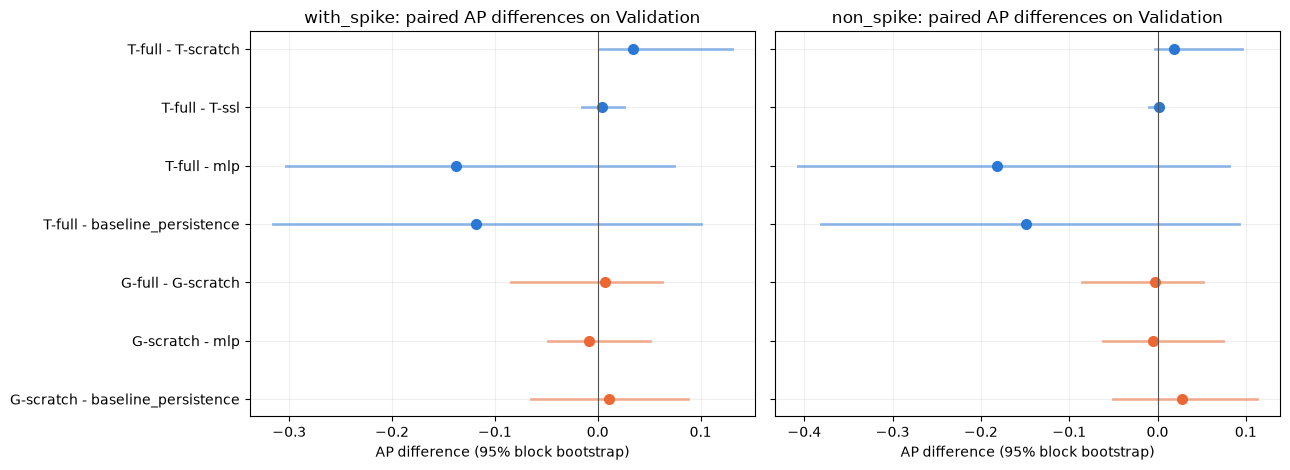

In [24]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
tl = root / "outputs" / "experiments" / "transfer_learning"
ARMS = ["T-scratch", "T-ssl", "T-full", "T-probe", "G-scratch", "G-ssl", "G-full", "G-probe"]
HUE = {"T": "#2a78d6", "G": "#eb6834", "mlp": "#1baf7a", "baseline_persistence": "#8a8984"}

extra = json.loads((tl / "report" / "gru_vs_baselines.json").read_text(encoding="utf-8"))
rows, criteria, seeds = [], [], []
for variant in ("with_spike", "non_spike"):
    summary = json.loads((tl / variant / "validation_summary.json").read_text(encoding="utf-8"))
    pairs = {**summary["paired_ap_differences"], **extra[variant]["validation"]}
    for name in ("T-full - T-scratch", "T-full - T-ssl", "T-full - mlp", "T-full - baseline_persistence",
                 "G-full - G-scratch", "G-scratch - mlp", "G-scratch - baseline_persistence"):
        d = pairs[name]
        rows.append({"variant": variant, "comparison": name, "AP difference": d["point"], "95% low": d["low"],
                     "95% high": d["high"], "excludes zero": d["excludes_zero"]})
    criteria.append({"variant": variant, **summary["criteria"]})
    for row in summary["leaderboard"]:
        if "seed_ap" in row:
            seeds.append({"variant": variant, "arm": row["model"], **{f"seed {s}": v for s, v in row["seed_ap"].items()},
                          "ensemble AP": row["average_precision"]})
table = pd.DataFrame(rows)
display(table.round(4))
display(pd.DataFrame(criteria))
display(pd.DataFrame(seeds).sort_values(["variant", "arm"]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, variant in zip(axes, ("with_spike", "non_spike")):
    part = table[table["variant"] == variant].reset_index(drop=True)
    for i, r in part.iterrows():
        color = HUE["T"] if r["comparison"].startswith("T-") else HUE["G"]
        ax.plot([r["95% low"], r["95% high"]], [i, i], color=color, linewidth=2, alpha=0.5)
        ax.plot(r["AP difference"], i, "o", color=color, markersize=7)
    ax.axvline(0, color="#52514e", linewidth=0.8)
    ax.set_yticks(range(len(part)), part["comparison"])
    ax.set(title=f"{variant}: paired AP differences on Validation", xlabel="AP difference (95% block bootstrap)")
    ax.grid(alpha=0.2)
axes[0].invert_yaxis()  # shared y: invert once
fig.tight_layout()
plt.show()


**สรุปบน Validation:**

- **เกณฑ์ข้อแรกผ่านทั้งสอง variant:** pretraining ช่วย Transformer (`T-full − T-scratch` = +0.035 [+0.002, +0.131] สำหรับ with_spike) แต่เป็นการช่วยให้โมเดลที่แย่กว่าการเดาสุ่มดีขึ้นเล็กน้อยเท่านั้น
- **เกณฑ์ข้อที่สองไม่ผ่าน:** Transformer แย่กว่า MLP และ persistence ส่วน GRU เสมอกับ MLP (ช่วงคร่อมศูนย์)
- **DAPT แทบไม่เพิ่มอะไร:** `T-full − T-ssl` ใกล้ศูนย์
- **pretraining ไม่ช่วย GRU:** `G-full − G-scratch` คร่อมศูนย์